# Wrangling Harmonic-EEG Data

**Group 18:** Ana Maria Ramirez Diaz, Davis Bone, Payton Shen, Rose Friedman, Trent Rogers

This notebook prepares the Harmonic-EEG dataset for analysis. The dataset has EEG recordings from 40 musicians, either classical musicians or jazz-trained improvisers, while they listened to three-chord progressions where the middle chord was occasionally changed. Before analyzing the EEG, we check who the participants are and that every participant's files are present and complete.

### Getting the data

The dataset is published on NEMAR ([doi.org/10.82901/nemar.on003570](https://doi.org/10.82901/nemar.on003570)) as a copy of OpenNeuro dataset `ds003570`. We downloaded NEMAR's `.zip` archive and unzipped it into a folder named `Data` next to this notebook. NEMAR offers other ways to download it too (NEMAR CLI, DataLad, git-annex, or direct file links).

The first cell below downloads the dataset with DataLad, but only if there is no `Data` folder yet:
- `datalad clone` downloads the small files (tables, `.json` files) and placeholders for the large EEG files
- `datalad get .` then downloads the large `.set` and `.fdt` EEG files (about 39 GB, so this takes a while)

The second cell adds up the size of every file in `Data` and reports:
- the number of files
- the total size in MB and GB
- how much of that is the EEG recordings (`.set` + `.fdt`) and how much is everything else

Note: the `.set` and `.fdt` files in `Data/sub-*/eeg/` are links to the real files, which are stored in the hidden `Data/.git` folder. The cell follows these links and skips `.git` itself, so each file is counted once.

In [1]:
import subprocess
from pathlib import Path

# NEMAR's copy of the dataset on GitHub, and the folder to put it in
data_url = "https://github.com/nemarDatasets/on003570.git"
root = Path("Data")

# Download the dataset only if the Data folder isn't here yet (needs DataLad installed)
if not root.exists():
    # Small files, plus placeholders for the large EEG files
    subprocess.run(["datalad", "clone", data_url, str(root)], check=True)
    # The large EEG files (about 39 GB)
    subprocess.run(["datalad", "get", "."], cwd=root, check=True)
else:
    print("Data folder already exists, skipping download")

Data folder already exists, skipping download


In [2]:
# Every file in the Data folder, skipping the hidden .git folder
# (the .set and .fdt files are links into .git, so they are counted through the links)
data_files = [f for f in root.rglob("*") if f.is_file() and ".git" not in f.parts]

# Total size of all files, in bytes
total_bytes = sum(f.stat().st_size for f in data_files)

# Size of just the EEG recordings (.set and .fdt files), in bytes
eeg_bytes = sum(f.stat().st_size for f in data_files if f.suffix in [".set", ".fdt"])

print(f"Files: {len(data_files)}")
print(f"Total size: {total_bytes / 1e6:,.0f} MB ({total_bytes / 1e9:.1f} GB)")
print(f"  EEG recordings (.set + .fdt): {eeg_bytes / 1e9:.1f} GB")
print(f"  Everything else: {(total_bytes - eeg_bytes) / 1e6:.1f} MB")

Files: 332
Total size: 38,783 MB (38.8 GB)
  EEG recordings (.set + .fdt): 38.8 GB
  Everything else: 10.2 MB


<details>
<summary><b>What's in <code>dataset_description.json</code></b> (click to expand)</summary>

`dataset_description.json` is the dataset's title page, required by the BIDS standard. It holds information about the dataset as a whole, not about any participant:
- the dataset's name ("EEG: Improvisation and Musical Structures"), version (1.0.0) and the BIDS version it follows (1.1.1)
- the authors, funding, ethics approval and acknowledgements
- the papers to cite (Goldman et al., 2020) and the license (CC0, free to use)
- its DOI on NEMAR, and that it was copied from OpenNeuro dataset `ds003570`

</details>

<details>
<summary><b>Hidden files in the <code>Data</code> folder</b> (click to expand)</summary>

Besides the data itself, the downloaded `Data` folder has a few hidden files and folders (names starting with `.`) used to manage and publish the dataset. None of them hold data we analyze:
- `.datalad/`: marks `Data` as a DataLad dataset (a tool for versioning and downloading large datasets) and stores its ID
- `.gitattributes`: tells git-annex (used by DataLad) which files to store as large files; here the big `.set` and `.fdt` EEG files are stored as links to the actual data
- `.github/`: automated checks the dataset's publishers run on GitHub, e.g. confirming the dataset follows the BIDS standard
- `.nemar/`: information for NEMAR, the website that hosts the dataset: a description of the study and a report confirming all 80 EEG files are present (it checks that the files exist, not that each recording is complete)
- `.bidsignore`: tells the BIDS validator to skip the `.nemar/` folder, since it isn't part of the BIDS standard

</details>

### Import libraries

Load the Python libraries used in this notebook: `pandas` for working with tables, `pathlib` for finding files in the `Data` folder, `json` for reading the dataset's `.json` metadata files, `numpy` for comparing lists of numbers, `scipy.io` for reading the MATLAB-format `.set` files, and `mne` for reading and cleaning the EEG (set to show only warnings, not progress messages).

In [3]:
import pandas as pd
from pathlib import Path
import json
import numpy as np
import scipy.io
import mne
mne.set_log_level("warning")

### Load and summarize participant information

`participants.tsv` has one row per participant with their ID, group (classical or improviser), handedness, age and gender. The cells below load it and summarize who is in the study:
- how many participants there are in total and in each group
- the average age and age range
- how many of each gender and handedness are in each group

In [4]:
# Load the TSV file into a DataFrame
participants_data = pd.read_csv('Data/participants.tsv', sep='\t')

# Convert to dataframe
df = pd.DataFrame(participants_data)

# Display the first few rows
df.head()

,participant_id,group,handedness,age,gender
0,sub-001,Cl,R,26,M
1,sub-002,Cl,R,26,M
2,sub-003,Cl,R,42,F
3,sub-004,Cl,R,24,F
4,sub-005,Imp,L,27,M


In [5]:
# Full names for the group codes used in the TSV
group_names = {"Cl": "classical musicians who don't improvise",
               "Imp": "improvisers (jazz-trained)"}

# Number of unique participants (participant_id is the primary key)
print(f"Participants: {df['participant_id'].nunique()}")

# Number of participants in each group
print("Group:")
for g, n in df["group"].value_counts().items():
    print(f"  {g} ({group_names[g]}): {n}")

# Mean and range of age
print(f"Age: mean {df['age'].mean():.1f}, range {df['age'].min()}–{df['age'].max()}")

# Number of participants of each gender
print("Gender:", df["gender"].value_counts().to_dict())

# Number of participants of each handedness
print("Handedness:", df["handedness"].value_counts().to_dict())

Participants: 40
Group:
  Imp (improvisers (jazz-trained)): 24
  Cl (classical musicians who don't improvise): 16
Age: mean 25.3, range 18–42
Gender: {'M': 24, 'F': 16}
Handedness: {'R': 31, 'A': 5, 'L': 4}


In [6]:
# Summary statistics for age
df["age"].agg(["count", "mean", "std", "min", "max"])

count    40.000000
mean     25.275000
std       5.514491
min      18.000000
max      42.000000
Name: age, dtype: float64

In [7]:
# Number of participants of each gender in each group
display(pd.crosstab(df["group"], df["gender"], margins=True))

# Number of participants of each handedness in each group
display(pd.crosstab(df["group"], df["handedness"], margins=True))

gender,F,M,All
group,,,
Cl,12,4,16
Imp,4,20,24
All,16,24,40


handedness,A,L,R,All
group,,,,
Cl,1,1,14,16
Imp,4,3,17,24
All,5,4,31,40


### Check that every participant has all their files

Each participant's `eeg` folder should contain the same set of files: the EEG recording itself (split into a `.set` header and an `.fdt` data file) plus smaller files describing the channels, electrodes and events. This cell lists every file with its size, then reports:
- any participant who is missing a file
- any EEG recording under 1 MB, which usually means it was never fully downloaded

In [8]:
root = Path("Data")

# List every file in each participant's eeg folder
rows = []
for file in sorted(root.glob("sub-*/eeg/*")):
    rows.append({
        # "sub-001_task-AuditoryOddballChords_events.tsv" -> "sub-001"
        "participant": file.name.split("_")[0],
        # "sub-001_task-AuditoryOddballChords_events.tsv" -> "events.tsv"
        "file": file.name.split("_")[-1],
        # Size in MB (0 if the file is a link to data that hasn't been downloaded)
        "size_MB": round(file.stat().st_size / 1e6, 2) if file.exists() else 0,
    })
files = pd.DataFrame(rows)

# Table with one row per participant and one column per file type (NaN = missing)
sizes = files.pivot(index="participant", columns="file", values="size_MB")

# Number of participants found
print(len(sizes), "participants found")

# Number of participants that have each file type (should all match the number above)
print("\nFiles per type:")
print(sizes.notna().sum())

# Participants missing at least one file type
missing = sizes[sizes.isna().any(axis=1)]
print("\nParticipants with missing files:")
print(missing if len(missing) else "  none")

# EEG recordings under 1 MB weren't fully downloaded
small = sizes.loc[(sizes["eeg.set"] < 1) | (sizes["eeg.fdt"] < 1), ["eeg.set", "eeg.fdt"]]
print("\nEEG recordings under 1 MB:")
print(small if len(small) else "  none")

40 participants found

Files per type:
file
channels.tsv        40
coordsystem.json    40
eeg.fdt             40
eeg.json            40
eeg.set             40
electrodes.tsv      40
events.json         40
events.tsv          40
dtype: int64

Participants with missing files:
  none

EEG recordings under 1 MB:
  none


### Check each participant's channels.tsv

`channels.tsv` lists the EEG channels (electrodes) in a recording. Under the BIDS standard it can have each channel's `name`, `type` (e.g. EEG or EOG), `units` (e.g. µV) and `status` (good or bad). This cell reads every participant's file and makes one row per participant showing:
- how many channels they have (should be 64)
- which columns their file has
- how many `type` and `units` values are missing (`n/a`)
- whether any channel name appears twice
- whether their channel list (names and order) matches everyone else's

In [9]:
# Read every participant's channels.tsv ("n/a" is read as missing)
channels = {f.name.split("_")[0]: pd.read_csv(f, sep="\t")
            for f in sorted(root.glob("sub-*/eeg/*_channels.tsv"))}

# The most common channel list (names in order), to compare each participant against
usual_names = pd.Series([tuple(c["name"]) for c in channels.values()]).mode()[0]

# One row per participant summarizing their channels.tsv
rows = []
for participant, c in channels.items():
    rows.append({
        "participant": participant,
        "n_channels": len(c),
        "columns": ", ".join(c.columns),
        "missing_type": c["type"].isna().sum(),
        "missing_units": c["units"].isna().sum(),
        "duplicate_names": c["name"].duplicated().sum(),
        "same_channels_as_others": tuple(c["name"]) == usual_names,
    })
channel_report = pd.DataFrame(rows).set_index("participant")

# How many participants share each combination of results (dropna=False keeps missing values)
channel_summary = channel_report.value_counts(dropna=False).to_frame("participants")
display(channel_summary)

# Full report only if participants' files differ
if len(channel_summary) > 1:
    display(channel_report)

,,,,,,participants
n_channels,columns,missing_type,missing_units,duplicate_names,same_channels_as_others,
64,"name, type, units",64,64,0,True,40


### Check each participant's coordsystem.json

`coordsystem.json` describes how to read the electrode positions in `electrodes.tsv`: which coordinate system they use and in what units. Under the BIDS standard it must have:
- `EEGCoordinateSystem`: the name of the coordinate system, or `Other` if it isn't a standard one
- `EEGCoordinateUnits`: the units of the positions (`m`, `mm`, `cm` or `n/a`)
- `EEGCoordinateSystemDescription`: a description of the system, required when it is `Other`

This cell reads every participant's file into one row per participant with one column per field (NaN = field missing). If every participant's file is the same, only a one-line summary is shown.

In [10]:
# Read every participant's coordsystem.json (one row per participant, one column per field)
rows = []
for f in sorted(root.glob("sub-*/eeg/*_coordsystem.json")):
    with open(f) as file:
        row = json.load(file)
    row["participant"] = f.name.split("_")[0]
    rows.append(row)
coord_report = pd.DataFrame(rows).set_index("participant")

# How many participants share each combination of values (dropna=False keeps missing fields)
coord_summary = coord_report.value_counts(dropna=False).to_frame("participants")
display(coord_summary)

# Full report only if participants' files differ
if len(coord_summary) > 1:
    display(coord_report)

,,,participants
EEGCoordinateUnits,EEGCoordinateSystem,EEGCoordinateSystemDescription,
mm,Other,EEGLAB,40


### Check each participant's electrodes.tsv

`electrodes.tsv` gives the position of each electrode on the head: its `name` and its `x`, `y`, `z` coordinates, in the coordinate system and units described in `coordsystem.json`. This cell reads every participant's file and makes one row per participant showing:
- how many electrodes they have (should be 64)
- which columns their file has
- how many values are missing (blank or `n/a`)
- whether their electrode names (in order) match everyone else's
- whether their electrode positions (x, y, z for each electrode, in order) match everyone else's

If every participant's results are the same, only a one-line summary is shown.

In [11]:
# Read every participant's electrodes.tsv ("n/a" and blanks are read as missing)
electrodes = {f.name.split("_")[0]: pd.read_csv(f, sep="\t")
              for f in sorted(root.glob("sub-*/eeg/*_electrodes.tsv"))}

# The most common electrode name list (in order), to compare each participant against
usual_electrodes = pd.Series([tuple(e["name"]) for e in electrodes.values()]).mode()[0]

# The most common set of positions (x, y, z for each electrode, in order), to compare against
usual_positions = pd.Series([tuple(e[["x", "y", "z"]].itertuples(index=False))
                             for e in electrodes.values()]).mode()[0]

# One row per participant summarizing their electrodes.tsv
rows = []
for participant, e in electrodes.items():
    rows.append({
        "participant": participant,
        "n_electrodes": len(e),
        "columns": ", ".join(e.columns),
        "missing_values": e.isna().sum().sum(),
        "same_names_as_others": tuple(e["name"]) == usual_electrodes,
        "same_positions_as_others": tuple(e[["x", "y", "z"]].itertuples(index=False)) == usual_positions,
    })
electrode_report = pd.DataFrame(rows).set_index("participant")

# How many participants share each combination of results (dropna=False keeps missing values)
electrode_summary = electrode_report.value_counts(dropna=False).to_frame("participants")
display(electrode_summary)

# Full report only if participants' files differ
if len(electrode_summary) > 1:
    display(electrode_report)

,,,,,participants
n_electrodes,columns,missing_values,same_names_as_others,same_positions_as_others,
64,"name, x, y, z",0,True,True,40


### Check each participant's events.json

`events.json` is meant to explain the columns of `events.tsv`: what each column means and what each event code stands for (for example, that `fourRoot_S` is a standard trial whose middle chord is IV in root position). Under the BIDS standard this file is optional, and when present it should be a JSON object (`{...}`).

In this dataset every participant's file is an empty list (`[]`). So, the meaning of the event codes has to come from the dataset README and the paper instead.

This cell reads every participant's file and makes one row per participant showing what kind of JSON it holds (BIDS expects `dict`) and how many entries it has. If every participant's results are the same, only a one-line summary is shown.

In [12]:
# Read every participant's events.json and record what it holds
rows = []
for f in sorted(root.glob("sub-*/eeg/*_events.json")):
    with open(f) as file:
        contents = json.load(file)
    rows.append({
        "participant": f.name.split("_")[0],
        # "dict" for a JSON object {...}, "list" for a JSON list [...]
        "json_type": type(contents).__name__,
        "n_entries": len(contents),
    })
events_json_report = pd.DataFrame(rows).set_index("participant")

# How many participants share each combination of results (dropna=False keeps missing values)
events_json_summary = events_json_report.value_counts(dropna=False).to_frame("participants")
display(events_json_summary)

# Full report only if participants' files differ
if len(events_json_summary) > 1:
    display(events_json_report)

,,participants
json_type,n_entries,
list,0,40


### Check each participant's events.tsv

`events.tsv` lists everything that happened during the recording, one row per event: when it happened (`onset`, in seconds from the start of the recording), how long it lasted (`duration`) and what it was (`value`). In this dataset all the information is in the `value` column:
- each trial is three chords 400 ms apart: `two` (the ii chord), a middle chord, then `one` (the I chord)
- the middle chord's code says which chord it was and what kind of trial it was, e.g. `fourRoot_S` = IV in root position on a standard trial, `five6_deviantE...` = an exemplar deviant, `four6_deviantF...` = a function deviant
- codes like `Correct - Function!` and the `correct`/`incorrect` endings appear to record the participant's responses (to confirm against the paper)
- `16128` marks the start of a block, and `boundary` marks where EEGLAB joined two blocks of recording together

This cell reads every participant's file and makes one row per participant showing the number of events, which columns are completely empty, missing values in the other columns, whether the events are in time order, the time of the last event, the number of different codes, and how many standard, exemplar deviant and function deviant trials there are. Checks where every participant has the same result are shown once; checks where they differ are shown for every participant. A last table lists every event code, how many participants have it, and the fewest and most times it appears for one participant.

In [13]:
# Read every participant's events.tsv ("n/a" and blanks are read as missing)
events = {f.name.split("_")[0]: pd.read_csv(f, sep="\t")
          for f in sorted(root.glob("sub-*/eeg/*_events.tsv"))}

# One row per participant summarizing their events.tsv
rows = []
for participant, e in events.items():
    rows.append({
        "participant": participant,
        "n_events": len(e),
        "columns": ", ".join(e.columns),
        # Columns with no values at all
        "empty_columns": ", ".join(e.columns[e.isna().all()]),
        # Number of missing values in each of the other columns, e.g. "missing_duration"
        **e.loc[:, e.notna().any()].isna().sum().add_prefix("missing_"),
        "onsets_in_order": e["onset"].is_monotonic_increasing,
        "last_onset_s": round(e["onset"].max()),
        "n_codes": e["value"].nunique(),
        # Middle-chord codes: "_S" = standard, "deviantE" = exemplar, "deviantF" = function
        "n_standard": e["value"].str.contains("_S").sum(),
        "n_exemplar_deviant": e["value"].str.contains("deviantE").sum(),
        "n_function_deviant": e["value"].str.contains("deviantF").sum(),
        "n_boundaries": (e["value"] == "boundary").sum(),
    })
events_report = pd.DataFrame(rows).set_index("participant")

# Checks where every participant has the same result, shown once
same_for_all = events_report.nunique(dropna=False) == 1
display(events_report.loc[:, same_for_all].iloc[0].to_frame("all participants"))

# Checks where participants differ, shown for every participant
display(events_report.loc[:, ~same_for_all])

# Every event code: how many participants have it, and the fewest / most times it appears
all_events = pd.concat(events, names=["participant", "row"]).reset_index()
code_counts = pd.crosstab(all_events["value"], all_events["participant"])
display(pd.DataFrame({"participants_with_code": (code_counts > 0).sum(axis=1),
                      "min_count": code_counts.min(axis=1),
                      "max_count": code_counts.max(axis=1)}))

,all participants
columns,"onset, duration, sample, trial_type, response_..."
empty_columns,"sample, response_time, stim_file"
missing_onset,0
missing_duration,7
missing_trial_type,0
missing_value,0
onsets_in_order,True
n_standard,1220
n_exemplar_deviant,109
n_function_deviant,111


,n_events,last_onset_s,n_codes
participant,,,
sub-001,4553,2350,23
sub-002,4583,2396,30
sub-003,4521,2343,30
sub-004,4566,2385,28
sub-005,4501,2445,28
sub-006,4553,2348,27
sub-007,4552,2337,26
sub-008,4732,2340,31
sub-009,4530,2347,29


,participants_with_code,min_count,max_count
value,,,
16128,39,0,8
16228,1,0,1
16368,2,0,1
Correct - Exemplar!,40,5,108
Correct - Function!,40,44,110
Incorrect - Standard!,39,0,270
boundary,40,7,7
five6_S,40,244,305
five6_Sincorrect,30,0,61


### Check each participant's eeg.json

`eeg.json` describes how a participant's EEG was recorded: the equipment (`ManufacturersModelName`), how many samples per second were taken (`SamplingFrequency`), how many channels of each kind there are (`EEGChannelCount`, `EOGChannelCount`, ...), the electrical reference, the mains power frequency, and how long the recording session lasted (`RecordingDuration`, in seconds).

This cell reads every participant's file into one row per participant with one column per field. Fields that are the same for everyone are shown once; fields that differ are shown for every participant.

In [14]:
# Read every participant's eeg.json (one row per participant, one column per field)
rows = []
for f in sorted(root.glob("sub-*/eeg/*_eeg.json")):
    with open(f) as file:
        row = json.load(file)
    row["participant"] = f.name.split("_")[0]
    rows.append(row)
eeg_json_report = pd.DataFrame(rows).set_index("participant")

# Number of fields missing across all files (a field one file has but another doesn't)
print("Missing fields:", eeg_json_report.isna().sum().sum())

# Fields where every participant has the same value, shown once
same_for_all = eeg_json_report.nunique(dropna=False) == 1
display(eeg_json_report.loc[:, same_for_all].iloc[0].to_frame("all participants"))

# Fields where participants differ, shown for every participant
display(eeg_json_report.loc[:, ~same_for_all])

Missing fields: 0


,all participants
InstitutionAddress,"550W 120th Street, New York, NY 10027, USA"
InstitutionName,"Columbia University, NY, USA"
InstitutionalDepartmentName,Laboratory for Intelligent Imaging and Neural ...
PowerLineFrequency,60
ManufacturersModelName,Biosemi - ActiveTwo
EEGChannelCount,64
TaskName,AuditoryOddballChords
MiscChannelCount,64
EEGReference,common
RecordingType,continuous


,RecordingDuration
participant,
sub-001,2354
sub-002,2402
sub-003,2347
sub-004,2390
sub-005,2449
sub-006,2350
sub-007,2339
sub-008,2341
sub-009,2351


### Check each participant's .set file

The EEG recording is stored in two files. The `.set` file is the header: a MATLAB file written by EEGLAB that describes the recording (number of channels, sampling rate, number of samples, channel names and positions, the event list) and names the `.fdt` file that holds the actual voltage values. The `.fdt` file can't be read without it, so it's checked first.

This cell opens every participant's `.set` file and lists any that can't be opened. For the rest, it makes one row per participant with the header values and checks that they agree with the participant's other files:
- the data file it points to is the participant's own `.fdt` file
- the channel names match `channels.tsv`
- the duration (samples ÷ sampling rate) matches `RecordingDuration` in `eeg.json`
- the event codes match the `value` column of `events.tsv`
- the event times match the `onset` column of `events.tsv`
- the electrode positions match `electrodes.tsv`
- no cleaning has been applied yet (no processing steps in the file's history, and no ICA)

It also shows the date each participant was recorded.

Checks where every participant has the same result are shown once; checks where they differ are shown for every participant.

In [15]:
# Read every participant's .set file (the header for their EEG recording)
rows = []
unreadable = []
for f in sorted(root.glob("sub-*/eeg/*_eeg.set")):
    participant = f.name.split("_")[0]
    try:
        EEG = scipy.io.loadmat(f, squeeze_me=True, struct_as_record=False)["EEG"]
    except OSError:
        # The file is cut short and can't be opened
        unreadable.append(participant)
        continue
    # Recording date, stored as [year, month, day, hour, minute, second]
    year, month, day = EEG.etc.T0[:3]
    rows.append({
        "participant": participant,
        "recording_date": f"{year}-{month:02d}-{day:02d}",
        "n_channels": EEG.nbchan,
        "sampling_rate": EEG.srate,
        "n_samples": EEG.pnts,
        "duration_s": EEG.pnts / EEG.srate,
        # Compare with the participant's other files
        "points_to_own_fdt": EEG.datfile == f.name.replace(".set", ".fdt"),
        "channels_match_channels_tsv": [c.labels for c in EEG.chanlocs] == list(channels[participant]["name"]),
        "duration_matches_eeg_json": EEG.pnts / EEG.srate == eeg_json_report.loc[participant, "RecordingDuration"],
        "events_match_events_tsv": [e.type for e in EEG.event] == list(events[participant]["value"]),
        # Event times are stored in samples, counting from 1
        "event_times_match_events_tsv": np.allclose([(e.latency - 1) / EEG.srate for e in EEG.event],
                                                    events[participant]["onset"]),
        # electrodes.tsv rounds positions to 2 decimals, so allow differences up to 0.005
        "positions_match_electrodes_tsv": np.allclose([[c.X, c.Y, c.Z] for c in EEG.chanlocs],
                                                      electrodes[participant][["x", "y", "z"]], atol=0.005),
        # No cleaning done: only EEGLAB's routine format check in the history, and no ICA
        "no_preprocessing": EEG.history.strip() == "EEG = eeg_checkset( EEG );" and np.size(EEG.icaweights) == 0,
    })
set_report = pd.DataFrame(rows).set_index("participant")

# Participants whose .set file can't be opened
print("Unreadable .set files:", unreadable)

# Checks where every participant has the same result, shown once
same_for_all = set_report.nunique() == 1
display(set_report.loc[:, same_for_all].iloc[0].to_frame("all readable files"))

# Checks where participants differ, shown for every participant
display(set_report.loc[:, ~same_for_all])

Unreadable .set files: ['sub-003', 'sub-004', 'sub-005', 'sub-013', 'sub-019', 'sub-022']


,all readable files
n_channels,64
sampling_rate,2048
points_to_own_fdt,True
channels_match_channels_tsv,True
duration_matches_eeg_json,True
events_match_events_tsv,True
event_times_match_events_tsv,True
positions_match_electrodes_tsv,True
no_preprocessing,True


,recording_date,n_samples,duration_s
participant,,,
sub-001,2017-02-07,4820992,2354.0
sub-002,2017-02-09,4919296,2402.0
sub-006,2017-03-02,4812800,2350.0
sub-007,2017-03-02,4790272,2339.0
sub-008,2017-03-03,4794368,2341.0
sub-009,2017-03-07,4814848,2351.0
sub-010,2017-03-07,4825088,2356.0
sub-011,2017-03-08,4808704,2348.0
sub-012,2017-03-08,4788224,2338.0


### Look inside a .set file

This shows everything stored in one participant's `.set` file (change `participant` to look at another; every readable file has the same fields). The tables are:
- **every field**: one row per field with its type, size (0 = empty) and a short preview
- **`chanlocs`**: the channel list, one row per channel, with its name (`labels`) and position (`X`, `Y`, `Z` and spherical coordinates)
- **`chaninfo`**: where the channel positions came from (`biosemi64.sph`, Biosemi's standard template layout, not measured on each participant) and which way the nose points (`+X`)
- **`event`**: the event list, one row per event, with its code (`type`), time in samples (`latency`, counting from 1) and its position in the original list (`urevent`)
- **`urevent`**: the original event list as recorded, before it was edited. Here each button press is the code `16224`; in `event` those were replaced by scored responses (e.g. `Correct - Function!`), and the middle chord was relabelled to say whether the response was correct. Its times (`latency`) restart at the beginning of each of the 8 blocks, so use `event` for timing
- **`reject`** and **`stats`**: where EEGLAB stores rejected data and data statistics; these are empty apart from EEGLAB's default display settings, as no cleaning has been done
- **`etc`**: the recording date and time (`T0`)

In [16]:
# Pick a participant to look inside their .set file
participant = "sub-001"
EEG = scipy.io.loadmat(next(root.glob(f"{participant}/eeg/*_eeg.set")),
                       squeeze_me=True, struct_as_record=False)["EEG"]

def preview(value):
    # A group of named sub-fields: list the sub-field names
    if isinstance(value, scipy.io.matlab.mat_struct):
        return "sub-fields: " + ", ".join(value._fieldnames)
    # A list of groups (e.g. one per event): list the sub-field names of the first one
    if isinstance(value, np.ndarray) and value.size and isinstance(value.flat[0], scipy.io.matlab.mat_struct):
        return "each entry has: " + ", ".join(value.flat[0]._fieldnames)
    return str(value)[:100]

# One row per field in the .set file
rows = []
for field in EEG._fieldnames:
    value = getattr(EEG, field)
    rows.append({"field": field, "type": type(value).__name__,
                 "size": np.size(value), "preview": preview(value)})
display(pd.DataFrame(rows).set_index("field"))

# Every field with more inside it, in the same order as the table above
for field in EEG._fieldnames:
    value = getattr(EEG, field)
    # A group of sub-fields: one row per sub-field
    if isinstance(value, scipy.io.matlab.mat_struct):
        print(field)
        display(pd.DataFrame([{"sub-field": k, "size": np.size(getattr(value, k)),
                               "preview": preview(getattr(value, k))}
                              for k in value._fieldnames]).set_index("sub-field"))
    # A list of groups (e.g. one per event): one row per entry, one column per sub-field
    elif isinstance(value, np.ndarray) and value.size and isinstance(value.flat[0], scipy.io.matlab.mat_struct):
        print(field)
        display(pd.DataFrame([{k: getattr(entry, k) for k in entry._fieldnames} for entry in value]))

,type,size,preview
field,,,
setname,str,1,context
filename,str,1,sub-001_task-AuditoryOddballChords_eeg.set
filepath,str,1,/media/datadrive/josef-home/_DATA_LIINC/MUSIC_...
subject,ndarray,0,[]
group,ndarray,0,[]
condition,ndarray,0,[]
session,ndarray,0,[]
comments,str,1,Original file: /Volumes/GOLDMAN BACKUP/MMN Fun...
nbchan,int,1,64


chanlocs


,sph_theta,sph_phi,labels,theta,radius,sph_radius,X,Y,Z,type,ref,urchan
0,18,-2,Fp1,-18.0,0.511111,1,0.950477,0.308829,-0.034899,[],[],1
1,36,-2,AF7,-36.0,0.511111,1,0.808524,0.587427,-0.034899,[],[],2
2,25,16,AF3,-25.0,0.411111,1,0.871199,0.406247,0.275637,[],[],3
3,22,40,F1,-22.0,0.277778,1,0.710264,0.286965,0.642788,[],[],4
4,39,30,F3,-39.0,0.333333,1,0.673028,0.545007,0.500000,[],[],5
...,...,...,...,...,...,...,...,...,...,...,...,...
59,-126,-2,P8,126.0,0.511111,1,-0.587427,-0.808524,-0.034899,[],[],60
60,-130,-25,P10,130.0,0.638889,1,-0.582563,-0.694272,-0.422618,[],[],61
61,-144,-2,PO8,144.0,0.511111,1,-0.808524,-0.587427,-0.034899,[],[],62
62,-155,16,PO4,155.0,0.411111,1,-0.871199,-0.406247,0.275637,[],[],63


chaninfo


,size,preview
sub-field,,
filename,1,/Users/AndrewGoldman/Desktop/Columbia Document...
filecontent,64,['1\t18\t-2\tFp1 ' '2\t36\t-2\tAF7 ' '3\...
plotrad,0,[]
shrink,0,[]
nosedir,1,+X
nodatchans,0,[]
icachansind,0,[]


event


... (5 outputs left out)

stats


,size,preview
sub-field,,
jp,0,[]
jpE,0,[]
icajp,0,[]
icajpE,0,[]
kurt,0,[]
kurtE,0,[]
icakurt,0,[]
icakurtE,0,[]
compenta,0,[]


etc


,size,preview
sub-field,,
T0,6,[2017 2 7 20 29 27]


### Check each participant's .fdt file

The `.fdt` file holds the EEG itself: the voltage (in µV) at every channel at every time point, stored as one long list of 32-bit numbers with no labels. They are in time order, all 64 channels for the first time point, then all 64 for the next, and so on, so the list can be cut into a table with one row per time point and one column per channel. The recording has 2048 time points per second.

This cell makes one row per participant showing:
- how many time points the file holds, and what percentage that is of the expected number (`RecordingDuration` × `SamplingFrequency` from `eeg.json`)
- whether the file stops part-way through a time point, a sign it was cut off
- how many values are missing or invalid (NaN or infinite)
- channels that never change (flat)
- channels stuck at the Biosemi recording limit (±262,144 µV) for most of the recording, which usually means the electrode wasn't working
- the typical size of the channels' ups and downs (median standard deviation, in µV)

The flat, stuck and size checks use one time point per second, which is enough to see each channel's overall behaviour. Reading all 40 files takes about a minute.

In [17]:
# Read every participant's .fdt file (the EEG voltages, in µV)
rows = []
for f in sorted(root.glob("sub-*/eeg/*_eeg.fdt")):
    participant = f.name.split("_")[0]
    names = np.array(channels[participant]["name"])
    rate = eeg_json_report.loc[participant, "SamplingFrequency"]
    expected = eeg_json_report.loc[participant, "RecordingDuration"] * rate

    # One long list of 32-bit numbers (memmap reads it from disk as needed instead of all at once)
    values = np.memmap(f, dtype="<f4", mode="r")
    # Cut it into a table: one row per time point, one column per channel
    n_samples = values.size // len(names)
    data = values[: n_samples * len(names)].reshape(n_samples, len(names))
    # One time point per second, enough to see each channel's overall behaviour
    per_second = np.asarray(data[::rate])

    rows.append({
        "participant": participant,
        "n_samples": n_samples,
        "pct_of_expected": round(100 * n_samples / expected, 1),
        # Leftover values after the last full time point: the file stops part-way through one
        "ends_mid_sample": values.size % len(names) != 0,
        "invalid_values": int((~np.isfinite(data)).sum()),
        # Channel names, or "none" if there aren't any
        "flat_channels": ", ".join(names[per_second.std(axis=0) == 0]) or "none",
        # Near the ±262,144 µV limit for more than half the recording
        "channels_stuck_at_limit": ", ".join(names[np.median(np.abs(per_second), axis=0) > 250000]) or "none",
        "median_channel_sd_uV": round(float(np.median(per_second.std(axis=0)))),
    })
fdt_report = pd.DataFrame(rows).set_index("participant")

# Participants whose file holds less than the full recording
print("Incomplete recordings:", list(fdt_report.index[fdt_report["pct_of_expected"] < 100]))

# Checks where every participant has the same result, shown once
same_for_all = fdt_report.nunique() == 1
display(fdt_report.loc[:, same_for_all].iloc[0].to_frame("all participants"))

# Checks where participants differ, shown for every participant
display(fdt_report.loc[:, ~same_for_all])

Incomplete recordings: ['sub-001', 'sub-003', 'sub-004', 'sub-005', 'sub-007', 'sub-010', 'sub-013', 'sub-019', 'sub-022', 'sub-025', 'sub-026', 'sub-030']


,all participants
invalid_values,0
flat_channels,none


,n_samples,pct_of_expected,ends_mid_sample,channels_stuck_at_limit,median_channel_sd_uV
participant,,,,,
sub-001,4443361,92.2,True,none,740
sub-002,4919296,100.0,False,Fp1,720
sub-003,83712,1.7,False,Fp1,100
sub-004,68460,1.4,True,Fp1,38
sub-005,77184,1.5,False,Fp1,22
sub-006,4812800,100.0,False,Fp1,1905
sub-007,372641,7.8,True,Fp1,138
sub-008,4794368,100.0,False,"Fp1, P3",837
sub-009,4814848,100.0,False,"Fp1, Fpz",915


### Summary

#### What we found

**Participants**
- 40 participants: 16 classical musicians (`Cl`) and 24 jazz-trained improvisers (`Imp`), aged 18–42.
- Gender is very unbalanced between groups: `Cl` is 12 women and 4 men, `Imp` is 4 women and 20 men.

**Files**
- Every participant has the same 8 files. `channels.tsv`, `electrodes.tsv`, `coordsystem.json` and `events.json` are identical for everyone; `eeg.json` differs only in the recording length.
- `channels.tsv`: all 64 channels are listed, but `type` and `units` are all `n/a` and there is no `status` (good/bad) column, so the dataset doesn't say which channels are bad.
- `coordsystem.json` and `electrodes.tsv`: the coordinate system and electrode positions are the same for every participant. The positions are a standard template (Biosemi's `biosemi64.sph`, textbook positions on a sphere), not measured on each person.
- Electrode names and channel names are the same, in the same order, in `channels.tsv`, `electrodes.tsv` and the `.set` file.
- `events.tsv`: every participant heard the same 1,440 trials (1,220 standard, 109 exemplar deviant, 111 function deviant), split into 8 blocks. Events are instantaneous markers (duration 0), except the 7 `boundary` events between blocks, which have no duration.
- `eeg.json` and `.set`: 64 EEG channels recorded at 2048 samples per second, with no cleaning done yet (raw data).
- `.fdt`: no missing or invalid values and no flat channels, but 12 recordings are incomplete and many have a channel that isn't working (see below).

#### Odd points that could cause confusion
- **Incomplete recordings.** 10 participants' EEG files hold only 1–8% of their recording (sub-003, 004, 005, 007, 010, 013, 019, 022, 025, 026), and 6 of their `.set` files can't be opened at all. sub-001 and sub-030 hold about 92%. This is how the files were published, not a download problem, and the checks that only ask "is the file there?" (including NEMAR's own report) don't catch it. Their `events.tsv` and `eeg.json` still describe the full session.
- **Stuck channels.** Fp1 is stuck at the recording limit (about 259,000 µV) for the whole recording in 26 participants, Fpz in 8, and P2 or P3 in a few others. These channels hold no usable EEG.
- **Values look far too large.** Channels vary by hundreds to thousands of µV instead of the usual tens, because raw Biosemi data has large offsets and slow drift until it is re-referenced and filtered. This is expected, not an error.
- **Labels that are wrong or misleading:**
  - `coordsystem.json` says positions are in mm, but they lie on a sphere of radius 1.
  - `eeg.json` says `MiscChannelCount: 64`, but the files hold only the 64 EEG channels.
  - `events.json` is an empty list (`[]`), so the event codes aren't documented in the dataset.
  - Every event's `trial_type` is `STATUS`, the name of the trigger channel; the real information is in `value`.
  - Channel `Afz` should be spelled `AFz` (EEG software matches names exactly).
- **README doesn't match the files.** The README says 218 exemplar and 222 function deviants per participant, but every file has 109 and 111, which matches the README's own "7.5% each". It also says the order of the 8 blocks was shuffled for every participant, but all 40 participants have exactly the same sequence of 1,440 trials.
- **Event codes include responses.** `Correct - Function!` and similar codes, and the `correct`/`incorrect` endings on middle-chord codes, are scored button presses. They were added after recording (the original list in the `.set` file has a plain `16224` code for each press).
- **`16128` block markers are unreliable** (missing for sub-024 and once for sub-040); the `boundary` events mark the blocks reliably.

## Data Cleaning and Preprocessing

Turning the raw recordings into clean trials, one step at a time. Each step says what it does and why, and checks the result.

### Step 1: Choose participants

Ten participants' EEG files hold only 1–8% of their recording (15–111 trials, with 0–15 deviants), so they are excluded. Their missing EEG isn't imputed: filling it in from other participants would invent brain responses and copy training participants' data into test participants'. sub-001 and sub-030 hold about 92%, so they are kept, using only their recorded trials. This leaves 30 participants.

The first cell makes `participant_table`, one row per participant with their status (`complete`, `partial` or `excluded`), and shows those who aren't complete. The second checks:
- how many are included in each group (should be 12 `Cl`, 18 `Imp`)
- that the 6 unreadable `.set` files all belong to excluded participants
- the group and gender of each status, to see whether the missing data comes mostly from one kind of participant
- the age of each status

In [18]:
# Participant information, plus the percentage of each EEG recording that exists
participant_table = df.set_index("participant_id")[["group", "gender", "age"]]
participant_table["pct_recorded"] = fdt_report["pct_of_expected"]

# Status: excluded (under 50%), partial (50% to under 100%) or complete (100%)
participant_table["status"] = pd.cut(participant_table["pct_recorded"], bins=[0, 50, 99.9, 100],
                                     labels=["excluded", "partial", "complete"])

# Participants who aren't complete
participant_table[participant_table["status"] != "complete"]

,group,gender,age,pct_recorded,status
participant_id,,,,,
sub-001,Cl,M,26,92.2,partial
sub-003,Cl,F,42,1.7,excluded
sub-004,Cl,F,24,1.4,excluded
sub-005,Imp,M,27,1.5,excluded
sub-007,Imp,M,25,7.8,excluded
sub-010,Cl,F,22,1.3,excluded
sub-013,Imp,M,25,1.2,excluded
sub-019,Imp,M,23,1.8,excluded
sub-022,Cl,F,24,1.4,excluded


In [19]:
included = participant_table[participant_table["status"] != "excluded"]

# Number included in each group
print("Included:", included["group"].value_counts().to_dict())

# The unreadable .set files should all belong to excluded participants
print("Unreadable .set files all excluded:", (participant_table.loc[unreadable, "status"] == "excluded").all())

# Group and gender of each status
display(pd.crosstab([participant_table["group"], participant_table["gender"]],
                    participant_table["status"], margins=True))

# Age of each status
participant_table.groupby("status")["age"].agg(["mean", "min", "max"]).round(1)

Included: {'Imp': 18, 'Cl': 12}
Unreadable .set files all excluded: True


status        excluded  partial  complete  All
group gender                                  
Cl    F              4        0         8   12
      M              0        1         3    4
Imp   F              0        1         3    4
      M              6        0        14   20
All                 10        2        28   40

,mean,min,max
status,,,
excluded,24.9,18,42
partial,30.0,26,34
complete,25.1,18,35


**Result:**
- 30 participants are included: 12 `Cl` and 18 `Imp`.
- All 10 excluded are `Cl` women or `Imp` men, so group and gender stay strongly linked (women: 8 of 12 `Cl`, 4 of 18 `Imp`). A difference between groups could also be a difference between genders.
- Ages barely change; the oldest participant (42) is among the excluded.

### Step 2: Make the trial table

The model will classify the middle chord of each trial, so this table has one row per middle chord for the 30 included participants. It's built from `events.tsv` alone, and the EEG features will be added to it as columns later. Its columns:
- `participant`, `group`
- `block` (1–8, counting the `boundary` events) and `trial` (1–1,440, in order)
- `onset_s`: time of the middle chord, in seconds from the start of the recording
- `code`: the original event code
- `chord`: the middle chord (`fourRoot`, `four6`, `fiveRoot` or `five6`)
- `condition`: `standard`, `exemplar` or `function`, the label to predict
- `correct`: whether the response was scored correct (`_S` or `correct_` in the code)
- `recorded`: whether the EEG covers the middle chord and the 0.5 s after it (enough for a trial window that ends before the third chord, at 0.4 s)

`correct`, `block`, `trial` and `onset_s` are kept for checking and grouping, but must never be used to predict the condition: the response comes after the chord, and every participant heard the same trial order, so a trial's position gives its condition away.

In [20]:
# One row per middle chord, for each included participant
tables = []
for participant in included.index:
    e = events[participant]
    # Block number: 1 plus the number of "boundary" events (joins between blocks) so far
    block = (e["value"] == "boundary").cumsum() + 1
    # Middle chords are the codes containing "_S" (standard) or "deviant"
    middle = e["value"].str.contains("_S|deviant")
    tables.append(pd.DataFrame({
        "participant": participant,
        "group": included.loc[participant, "group"],
        "block": block[middle],
        "trial": range(1, middle.sum() + 1),
        "onset_s": e.loc[middle, "onset"],
        "code": e.loc[middle, "value"],
    }))
trials = pd.concat(tables, ignore_index=True)

# Chord: the part of the code before the first "_", e.g. "four6_deviantE" -> "four6"
trials["chord"] = trials["code"].str.split("_").str[0]

# Condition: "_S" = standard, "_deviantE" = exemplar, "_deviantF" = function
trials["condition"] = trials["code"].str.extract(r"_(S|deviantE|deviantF)")[0].map(
    {"S": "standard", "deviantE": "exemplar", "deviantF": "function"})

# Correct: standards with no response ("_S" at the end) and deviants scored "correct_"
trials["correct"] = trials["code"].str.endswith("_S") | trials["code"].str.contains("correct_")

# Recorded: the EEG continues for at least 0.5 s after the middle chord
recorded_s = fdt_report["n_samples"] / eeg_json_report["SamplingFrequency"]
trials["recorded"] = trials["onset_s"] + 0.5 < trials["participant"].map(recorded_s)

trials.head()

,participant,group,block,trial,onset_s,code,chord,condition,correct,recorded
0,sub-001,Cl,1,1,3.551270,fourRoot_S,fourRoot,standard,True,True
1,sub-001,Cl,1,2,5.145020,fourRoot_S,fourRoot,standard,True,True
2,sub-001,Cl,1,3,6.745117,fourRoot_S,fourRoot,standard,True,True
3,sub-001,Cl,1,4,8.338379,fourRoot_S,fourRoot,standard,True,True
4,sub-001,Cl,1,5,9.945801,fourRoot_S,fourRoot,standard,True,True


The check cell reports:
- the number of trials of each condition per participant (should be 1,220 / 109 / 111 for everyone) and per block (should be 180)
- the time between trials within a block (should be about 1.6 s, the trial length)
- the number of trials in each condition, overall and by group (the class balance)
- the trials outside the recorded EEG, by participant and condition
- the percentage of correct responses in each condition, by group

In [21]:
# Trials of each condition per participant (identical rows are counted together)
display(pd.crosstab(trials["participant"], trials["condition"]).value_counts().to_frame("participants"))

# Trials per block
print("Trials per block:", trials.groupby(["participant", "block"]).size().unique())

# Time between trials within a block, in seconds
print("Seconds between trials:", trials.groupby(["participant", "block"])["onset_s"].diff().describe().round(2).to_dict())

# Number of trials in each condition, overall and by group
display(pd.crosstab(trials["group"], trials["condition"], margins=True))

# Trials outside the recorded EEG, by participant and condition
not_recorded = trials[~trials["recorded"]]
display(pd.crosstab(not_recorded["participant"], not_recorded["condition"], margins=True))

# Percentage of correct responses in each condition, by group
pd.crosstab(trials["condition"], trials["group"], values=trials["correct"], aggfunc="mean").mul(100).round(1)

,,,participants
exemplar,function,standard,
109,111,1220,30


Trials per block: [180]
Seconds between trials: {'count': 42960.0, 'mean': 1.6, 'std': 0.01, 'min': 1.57, '25%': 1.6, '50%': 1.6, '75%': 1.6, 'max': 1.78}


condition,exemplar,function,standard,All
group,,,,
Cl,1308,1332,14640,17280
Imp,1962,1998,21960,25920
All,3270,3330,36600,43200


condition,exemplar,function,standard,All
participant,,,,
sub-001,10,6,97,113
sub-030,10,6,93,109
All,20,12,190,222


group,Cl,Imp
condition,,
exemplar,68.5,63.6
function,76.3,77.0
standard,90.3,94.7


**Result:**
- Every participant has 1,440 trials (1,220 standard, 109 exemplar, 111 function) in 8 blocks of 180, about 1.6 s apart, as designed.
- The classes are very unbalanced: 84.7% standard, 7.6% exemplar, 7.7% function (43,200 trials in total). A model that always says "standard" would be 85% accurate, so accuracy alone can't be used to judge models.
- 222 trials come after the end of sub-001's and sub-030's recordings, spread across conditions in about the same proportions. They stay in the table with `recorded` = false.
- Participants caught exemplar deviants less often (64–69%) than function deviants (76–77%), with little difference between groups.

### Step 3: Load one participant's EEG with MNE

MNE is a Python library for EEG. It reads the `.set` and `.fdt` files together and has the tools for the next steps (filtering, re-referencing, cutting trials). Each step is set up and checked on one complete participant (sub-002) before running it on all 30.

The cell loads the recording, then:
- cuts it at its last recorded sample (this only changes sub-001 and sub-030, whose files stop early and otherwise can't be loaded)
- renames `Afz` to `AFz`, so MNE recognises the channel
- gives each channel Biosemi's standard 64-channel position (the same template the dataset uses)
- marks the channels stuck at the recording limit as bad, so later steps leave them out until they are filled in (step 7)

MNE warns that the recording has `boundary` events (the joins between blocks); filtering in step 5 deals with these. One recording takes about 2.5 GB of memory.

In [22]:
# A complete participant to set up each step on
participant = "sub-002"

# Open the recording (the .set file points MNE to the .fdt file)
raw = mne.io.read_raw_eeglab(next(root.glob(f"{participant}/eeg/*_eeg.set")))

# Cut at the last recorded sample, then read the EEG into memory
raw.crop(tmax=(fdt_report["n_samples"][participant] - 1) / raw.info["sfreq"])
raw.load_data()

# Fix the channel name, then use Biosemi's standard 64-channel positions
raw.rename_channels({"Afz": "AFz"})
raw.set_montage("biosemi64")

# Mark the channels stuck at the recording limit as bad
stuck = fdt_report["channels_stuck_at_limit"][participant]
raw.info["bads"] = [] if stuck == "none" else stuck.split(", ")

/var/folders/tz/dtb_3rdj0j73z9pzh5q2bm5h0000gn/T/ipykernel_9796/127405981.py:5: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(next(root.glob(f"{participant}/eeg/*_eeg.set")))


The check cell reports:
- the number of channels, sampling rate and length (should be 64 channels, 2048 Hz, and the length in `eeg.json`)
- the bad channels
- whether MNE's events (called annotations) match `events.tsv`, and the number of `boundary` events (should be 7)
- a map of the electrode positions, with bad channels in red
- 10 seconds of EEG on every channel, starting 60 s in. Bad channels are grey and the coloured lines are events.

Channels: 64 | Sampling rate: 2048.0 Hz | Length: 2402.0 s (eeg.json: 2402 s)
Bad channels: ['Fp1']
Events match events.tsv: True
Boundary events: 7


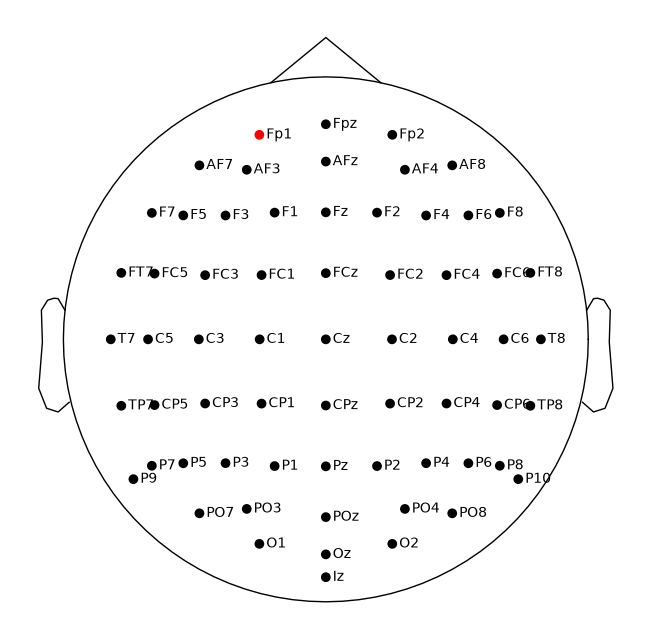

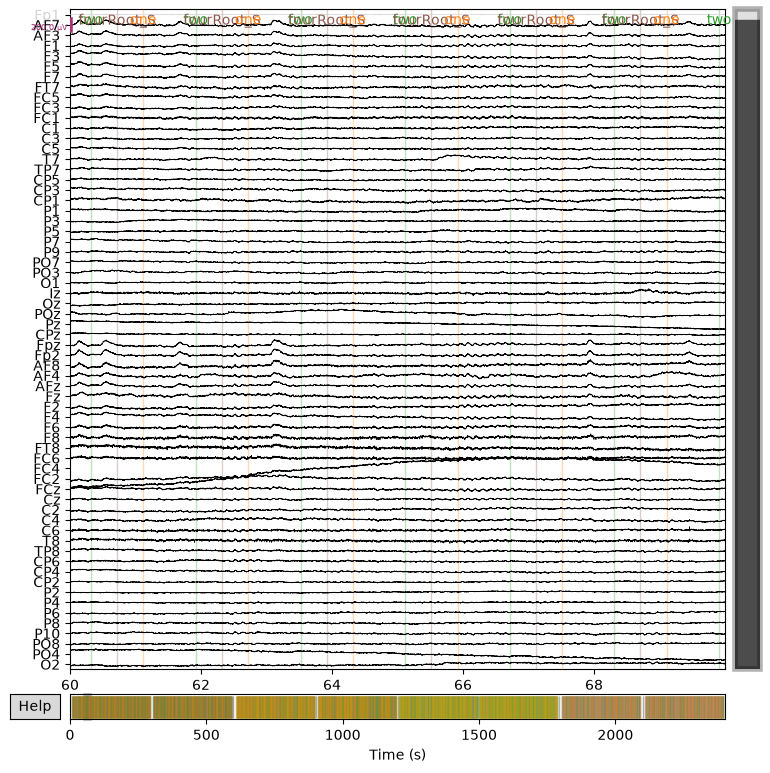

In [23]:
# Channels, sampling rate and length
print("Channels:", len(raw.ch_names), "| Sampling rate:", raw.info["sfreq"], "Hz",
      "| Length:", raw.n_times / raw.info["sfreq"], "s (eeg.json:", eeg_json_report.loc[participant, "RecordingDuration"], "s)")

# Bad channels
print("Bad channels:", raw.info["bads"])

# MNE's annotations should have the same codes and times as events.tsv
e = events[participant]
print("Events match events.tsv:", list(raw.annotations.description) == list(e["value"].astype(str))
      and np.allclose(raw.annotations.onset, e["onset"]))
print("Boundary events:", (raw.annotations.description == "boundary").sum())

# Electrode positions (bad channels in red)
raw.plot_sensors(show_names=True)

# 10 seconds of EEG on every channel, on a 100 µV scale
raw.plot(start=60, duration=10, n_channels=64, scalings=dict(eeg=100e-6));

**Result:**
- sub-002 loads with 64 channels at 2048 Hz for its full 2,402 s, with Fp1 marked bad. All 4,583 events, including the 7 `boundary` events, match `events.tsv`.
- The front channels show large bumps every few seconds, probably eye blinks. These are removed with ICA in step 6. The slow drift in some channels is removed by filtering (step 5).

### Step 4: Downsample to 256 samples per second

The EEG was recorded at 2048 samples per second, far more than needed: the brain responses we study are below about 40 Hz, and 256 samples per second keeps everything up to 128 Hz. Keeping 1 sample in 8 makes the recording 8 times smaller, so every later step runs faster.

Downsampling smooths the signal slightly, and the 7 joins between blocks are sudden jumps. MNE's `polyphase` method keeps the effect of each jump within 0.05 s of the join (no trial is that close to one), while the default method spreads small errors (1–3 µV) for more than 30 s around each join.

The check cell reports:
- the new sampling rate and number of samples (should be 256 Hz and 8 times fewer samples)
- whether the middle-chord times still match the trial table
- the largest gap between a middle chord and the nearest sample (samples are now 3.9 ms apart, so this should be under 2 ms)

In [24]:
# Keep 256 samples per second
raw.resample(256, method="polyphase")

<RawEEGLAB | sub-002_task-AuditoryOddballChords_eeg.fdt, 64 x 614912 (2402.0 s), ~300.3 MiB, data loaded>

In [25]:
# New sampling rate and number of samples
print("Sampling rate:", raw.info["sfreq"], "Hz | Samples:", raw.n_times,
      "(before:", fdt_report.loc[participant, "n_samples"], ")")

# Event times are kept in seconds, so the middle chords should still match the trial table
middle_onsets = trials.loc[trials["participant"] == participant, "onset_s"].to_numpy()
annotation_onsets = raw.annotations.onset[np.isin(raw.annotations.description, trials["code"])]
print("Middle chords match trial table:", np.allclose(annotation_onsets, middle_onsets))

# Largest gap between a middle chord and the nearest sample, in ms
samples = middle_onsets * raw.info["sfreq"]
print("Largest gap to nearest sample:", round(np.abs(samples - samples.round()).max() / raw.info["sfreq"] * 1000, 2), "ms")

Sampling rate: 256.0 Hz | Samples: 614912 (before: 4919296 )
Middle chords match trial table: True
Largest gap to nearest sample: 1.95 ms


**Result:** sub-002 now has 256 samples per second (614,912 samples instead of 4,919,296), and takes about 300 MB of memory instead of 2.4 GB. The middle-chord times still match the trial table, and each is within 1.95 ms of a sample.

### Step 5: Filter

Filtering removes parts of the signal that change too slowly or too quickly to be the brain responses we study:
- a **high-pass** filter removes slow drift (the wandering baselines in the step 3 plot)
- a **low-pass** filter at 40 Hz removes fast noise, such as muscle activity and the 60 Hz mains hum

The 8 blocks were joined together, so each block is filtered separately (`skip_by_annotation="boundary"`). Otherwise the filter would smear the jumps at the joins into the data around them.

#### Choosing the high-pass cutoff

The cutoff is the slowest change the filter keeps. 0.1 Hz is the usual choice for these brain responses, but its filter is long, so it distorts the data near the start and end of each block. 0.5 Hz has a much shorter filter, but may change the shape of slow responses. This cell compares the two on sub-002:
- **reach**: how far the filter's effect reaches past a block edge (half the filter's length), and how many trials are that close to an edge
- **response**: the average response to deviants minus the response to standards, at Fz, FCz and Cz. This uses a quick version of the next steps (average reference, trials from −0.1 to 0.4 s), just for this comparison.

,cutoff_Hz,reach_s,trials_near_edge,deviants_near_edge
0,0.1,16.5,104,10
1,0.5,3.3,2,1


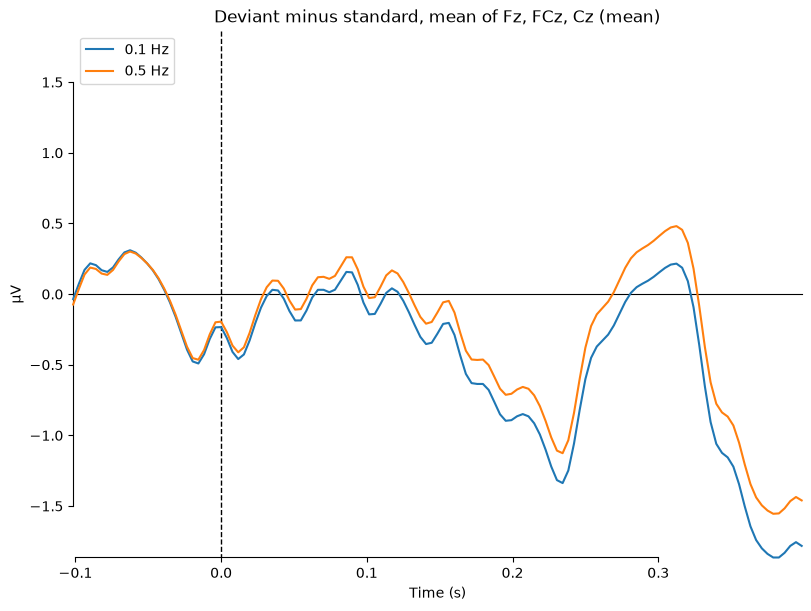

In [26]:
# Distance from each of sub-002's middle chords to the nearest block edge, in seconds
sub_trials = trials[trials["participant"] == participant]
edges = np.r_[0, raw.annotations.onset[raw.annotations.description == "boundary"], raw.times[-1]]
distance = np.abs(sub_trials["onset_s"].to_numpy()[:, None] - edges).min(axis=1)

# Middle chords as MNE events: sample, 0, and 1 = standard or 2 = deviant
event_array = np.c_[np.round(sub_trials["onset_s"] * raw.info["sfreq"]), np.zeros(len(sub_trials)),
                    np.where(sub_trials["condition"] == "standard", 1, 2)].astype(int)

reach_rows = []
differences = {}
for cutoff in [0.1, 0.5]:
    # How far the filter reaches past a block edge (half its length), and the trials that close to an edge
    reach = len(mne.filter.create_filter(None, raw.info["sfreq"], l_freq=cutoff, h_freq=None)) / raw.info["sfreq"] / 2
    near = distance < reach
    reach_rows.append({"cutoff_Hz": cutoff, "reach_s": round(reach, 1), "trials_near_edge": near.sum(),
                       "deviants_near_edge": (near & (sub_trials["condition"] != "standard")).sum()})

    # Quick average response: filter, average reference, cut trials, then deviant minus standard
    filtered = raw.copy().filter(cutoff, 40, skip_by_annotation="boundary").set_eeg_reference("average")
    epochs = mne.Epochs(filtered, event_array, {"standard": 1, "deviant": 2}, tmin=-0.1, tmax=0.4, preload=True)
    differences[f"{cutoff} Hz"] = mne.combine_evoked([epochs["deviant"].average(), epochs["standard"].average()], weights=[1, -1])

display(pd.DataFrame(reach_rows))
mne.viz.plot_compare_evokeds(differences, picks=["Fz", "FCz", "Cz"], combine="mean",
                             title="Deviant minus standard, mean of Fz, FCz, Cz");

**Comparison result:** the 0.1 Hz filter distorts the data for about 16.5 s after the start and before the end of each block, which puts 104 of sub-002's trials (10 deviants) in distorted stretches; 0.5 Hz reaches only 3.3 s, affecting 2 trials. The deviant-minus-standard response has the same shape with both cutoffs, so **we use 0.5 Hz**.

#### Apply the filter

The recording is filtered from 0.5 to 40 Hz, one block at a time. There is no separate 60 Hz (mains) filter, because the 40 Hz low-pass already removes it. We don't keep frequencies above 40 Hz: on the scalp these are mostly muscle activity, which could differ between trial types because participants tense up to press the button after a deviant.

The cell keeps the power spectrum (how much of the signal is at each frequency) from before filtering, then filters. The spectrum uses a stretch of block 2, because the jumps at the joins between blocks would blur it. The check cell shows:
- the power spectrum before and after filtering: after, the 60 Hz peak should be gone and power should drop steeply above 40 Hz
- the same 10 seconds of EEG as in step 3, now without the slow drift

In [27]:
# A stretch of block 2, away from the joins between blocks
boundaries = raw.annotations.onset[raw.annotations.description == "boundary"]
block_2 = dict(tmin=boundaries[0] + 10, tmax=boundaries[1] - 10)

# Power spectrum before filtering, to compare with afterwards
psd_before = raw.compute_psd(**block_2)

# Keep 0.5 to 40 Hz, filtering each block separately
raw.filter(l_freq=0.5, h_freq=40, skip_by_annotation="boundary")

<RawEEGLAB | sub-002_task-AuditoryOddballChords_eeg.fdt, 64 x 614912 (2402.0 s), ~300.3 MiB, data loaded>

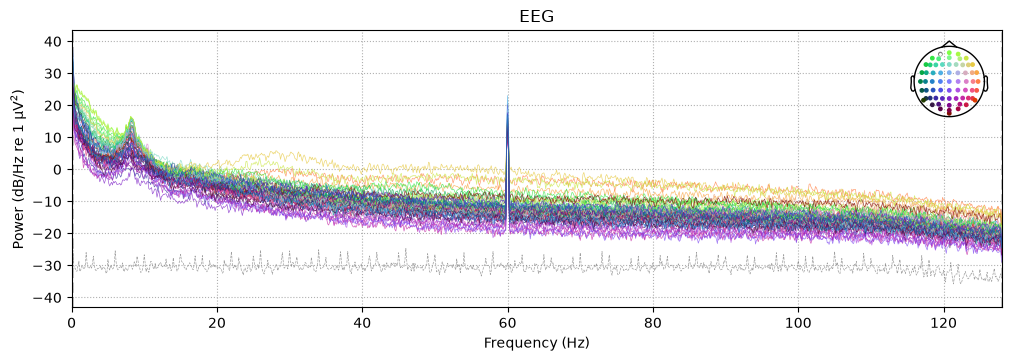

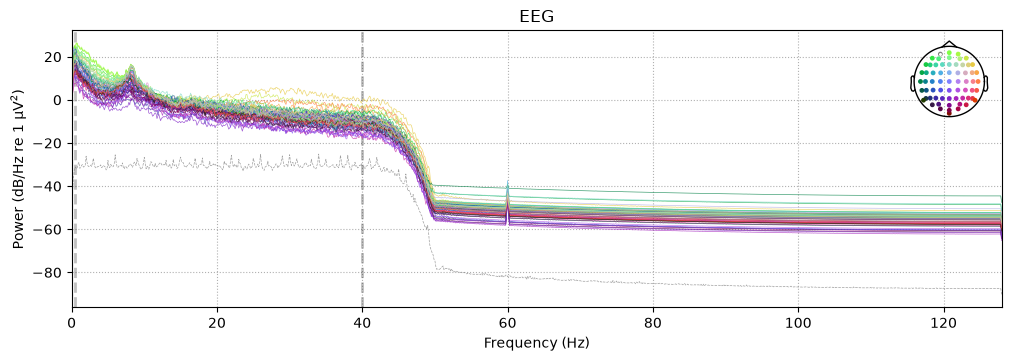

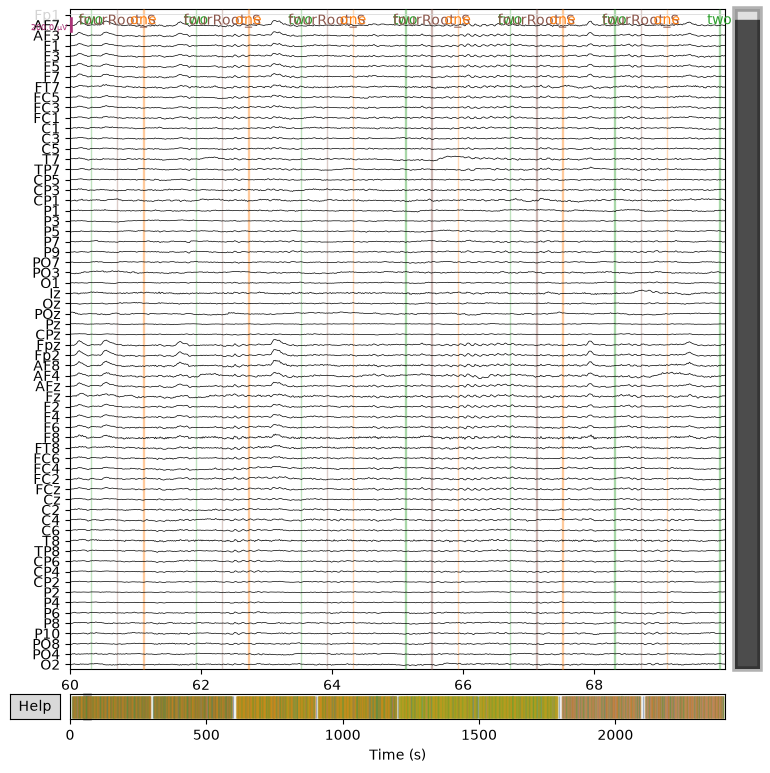

In [28]:
# Power spectrum of block 2 before and after filtering
psd_before.plot();
raw.compute_psd(**block_2).plot();

# The same 10 seconds as in step 3, after filtering
raw.plot(start=60, duration=10, n_channels=64, scalings=dict(eeg=100e-6));

**Result:** after filtering, the 60 Hz mains hum is about a million times weaker (a tiny blip remains, far below the brain signal), power above 45 Hz is over 5,000 times smaller, and the channels no longer drift. The peak near 9 Hz is the normal alpha rhythm. The eye blinks on the front channels remain; they are removed in step 6.

### Step 6: Remove eye blinks with ICA

Blinks cause large, slow swings on the front channels, much bigger than the brain responses. Left in, they would force many trials to be thrown away: 14% of trials overall, and up to 41% for some participants, in a first version of this cleaning without this step.

ICA (independent component analysis) splits the channels into 20 separate sources (components), each with its own pattern over the scalp. Blinks end up in one component, strongest at the front of the head. There are no separate eye channels, so the blink component is found as the one that rises and falls with Fp2, the front channel where blinks are largest (Fp1 and Fpz are stuck for many participants). Only components that clearly match Fp2 (correlation above 0.7) are removed. Weaker matches are spread over the front and centre of the head, where the brain responses we study are, so removing them could remove part of that signal; any eye activity left in a trial is still caught by the 150 µV rule in step 9.

ICA is fitted on a copy filtered from 1 Hz, which helps it separate the sources (`random_state` makes the result the same every run). It is fitted separately for each participant and never sees the trial labels, so it can't leak them.

The check cell shows:
- the blink components found, and how closely each matches Fp2 (correlation; 1 = identical)
- each blink component's pattern over the scalp (should be strongest at the front)
- the same 10 seconds of EEG as before, now without the blinks

In [29]:
# Split the good channels into 20 components (fitted on a copy filtered from 1 Hz)
ica = mne.preprocessing.ICA(n_components=20, random_state=97, max_iter="auto")
ica.fit(raw.copy().filter(l_freq=1, h_freq=None, skip_by_annotation="boundary"))

# Blink components: the ones that rise and fall with Fp2 (correlation above 0.7)
ica.exclude, blink_scores = ica.find_bads_eog(raw, ch_name="Fp2", measure="correlation", threshold=0.7)

# Remove the blink components from the data
ica.apply(raw)

<RawEEGLAB | sub-002_task-AuditoryOddballChords_eeg.fdt, 64 x 614912 (2402.0 s), ~300.3 MiB, data loaded>

Blink components: [np.int64(2)] | Correlation with Fp2: [0.91]


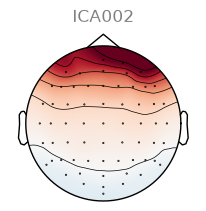

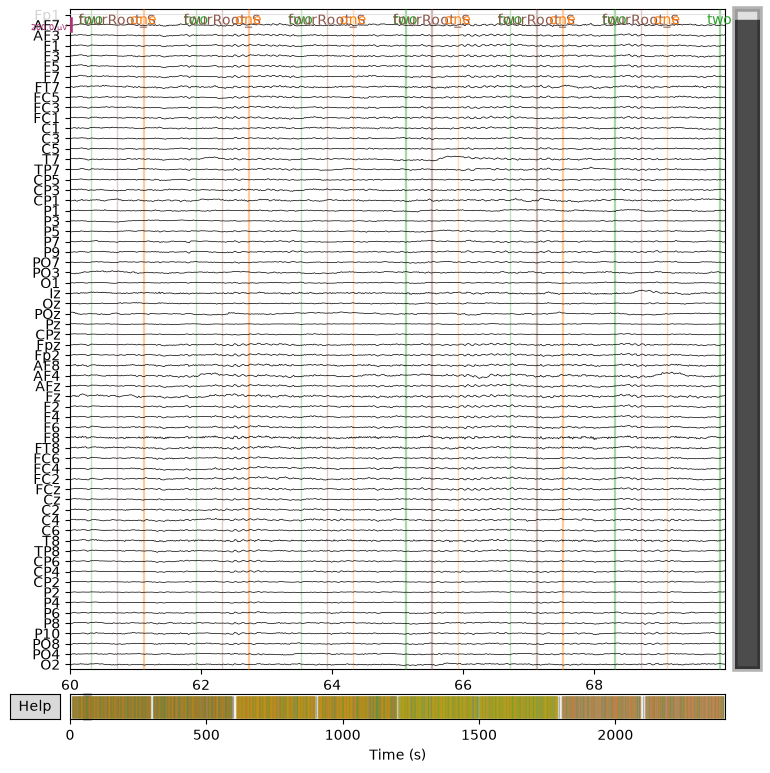

In [30]:
# Blink components and how closely each matches Fp2
print("Blink components:", ica.exclude, "| Correlation with Fp2:", np.abs(blink_scores[ica.exclude]).round(2))

# Pattern of each blink component over the scalp
ica.plot_components(picks=ica.exclude);

# The same 10 seconds as before, after removing blinks
raw.plot(start=60, duration=10, n_channels=64, scalings=dict(eeg=100e-6));

**Result:** ICA finds one blink component for sub-002, matching Fp2 closely (correlation 0.91) and strongest at the very front of the head. After removing it, the blinks are gone from the 10-second plot.

### Step 7: Find noisy channels and fill in the bad ones

Some channels are noisy for much of the recording, for example when an electrode loses good contact. In a first version of this cleaning, a single noisy channel caused most of the dropped trials for sub-036 (C4, 69% of trials) and sub-030 (TP8, 67%). A channel counts as noisy if, after blinks are removed, it swings by more than 150 µV (the trial noise limit used in step 9) in more than 10% of the participant's trials. This is measured on an average-referenced copy cut into trials, and only looks at how noisy each channel is, not at the trial labels.

All bad channels, stuck or noisy, are then filled in (interpolated) from their neighbouring channels, so every participant has all 64 channels and the average reference in step 8 uses all of them. This is the one place data is filled in: it works because the rest of the head was recorded at the same moments. A participant with more than 6 bad channels (about 10%) would be excluded, because too much of their head would be filled in rather than measured.

The cell defines `codes` (a number for each condition) and `trial_events`, which turns rows of the trial table into the events MNE uses to cut trials. The check cell shows:
- the channels most often over 150 µV, as a percentage of trials
- the channels filled in, and the bad channels left afterwards (should be none)

In [31]:
# A number for each condition, and a function turning trial-table rows into MNE events
# (sample number at 256 per second, 0, condition number)
codes = {"standard": 1, "exemplar": 2, "function": 3}
def trial_events(rows):
    return np.c_[np.round(rows["onset_s"] * 256), np.zeros(len(rows)), rows["condition"].map(codes)].astype(int)

# sub-002's recorded trials, cut from an average-referenced copy, good channels only
recorded_trials = trials[(trials["participant"] == participant) & trials["recorded"]]
test_epochs = mne.Epochs(raw.copy().set_eeg_reference("average"), trial_events(recorded_trials), codes,
                         tmin=-0.1, tmax=0.4, baseline=(None, 0), preload=True).pick("eeg", exclude="bads")

# Percentage of trials in which each channel swings by more than 150 µV
swing = np.ptp(test_epochs.get_data(), axis=2)
pct_over = pd.Series((swing > 150e-6).mean(axis=0) * 100, index=test_epochs.ch_names)

# Noisy channels: over 150 µV in more than 10% of trials. Then fill in all bad channels from their neighbours
raw.info["bads"] += list(pct_over.index[pct_over > 10])
filled_in_channels = list(raw.info["bads"])
raw.interpolate_bads()

<RawEEGLAB | sub-002_task-AuditoryOddballChords_eeg.fdt, 64 x 614912 (2402.0 s), ~300.3 MiB, data loaded>

In [32]:
# Channels most often over 150 µV, as a percentage of trials
print("Most often over 150 µV (% of trials):", pct_over.sort_values(ascending=False).head(5).round(1).to_dict())

# Channels filled in, and the bad channels left afterwards
print("Filled in:", filled_in_channels, "| Bad channels now:", raw.info["bads"])

Most often over 150 µV (% of trials): {'CP3': 0.4, 'Iz': 0.1, 'T7': 0.1, 'AF7': 0.1, 'C5': 0.1}
Filled in: ['Fp1'] | Bad channels now: []


**Result:** no channel is noisy for sub-002: the one most often over 150 µV is CP3, in 0.4% of trials. Only the stuck channel Fp1 is filled in, so all 64 channels are now usable.

### Step 8: Re-reference to the average

EEG measures the voltage between two points, so every channel is measured against a reference. Biosemi records against an electrode that isn't meant to be the final reference, so the data has to be re-referenced after recording. We use the average of all 64 channels (the bad ones were filled in during step 7): at every moment, the average across channels is subtracted from each channel. This removes signals that all channels share (such as noise picked up by the whole cap) and is the usual choice with 64 channels.

The cell keeps each channel's size before re-referencing (its standard deviation over block 2, in µV), then re-references. The check cell shows:
- the largest average across the channels at any moment (should be 0)
- the size of the channels before and after
- the same 10 seconds of EEG as before

In [33]:
# Size of each channel before re-referencing (standard deviation over block 2, in µV)
sd_before = raw.get_data(picks="eeg", **block_2).std(axis=1) * 1e6

# Subtract the average of all channels from every channel
raw.set_eeg_reference("average")

<RawEEGLAB | sub-002_task-AuditoryOddballChords_eeg.fdt, 64 x 614912 (2402.0 s), ~300.3 MiB, data loaded>

Largest average across channels: 0.0 µV


,before_uV,after_uV
count,64.0,64.0
mean,10.2,8.0
std,3.2,2.9
min,4.5,4.1
25%,8.3,6.1
50%,10.3,7.1
75%,11.7,9.0
max,18.9,17.0


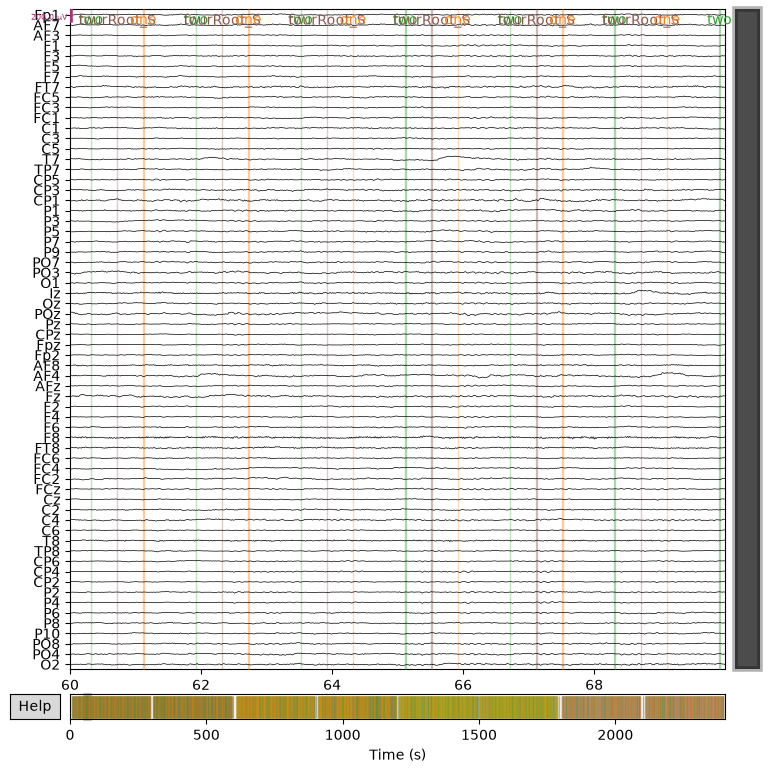

In [34]:
# All channels over block 2, in µV
data_uV = raw.get_data(picks="eeg", **block_2) * 1e6

# The average across channels should now be 0 at every moment
print("Largest average across channels:", round(np.abs(data_uV.mean(axis=0)).max(), 6), "µV")

# Size of the channels before and after (standard deviation, in µV)
display(pd.DataFrame({"before_uV": sd_before, "after_uV": data_uV.std(axis=1)}).describe().round(1))

# The same 10 seconds as before, after re-referencing
raw.plot(start=60, duration=10, n_channels=64, scalings=dict(eeg=100e-6));

**Result:** the average across channels is now 0 at every moment. The channels vary by about 4–17 µV (median 7 µV), less than before because the shared signal has been removed; filtering had already removed the large offsets.

### Step 9: Cut out the trials and mark the unusable ones

Each middle chord is cut out of the recording as its own short piece of EEG (an epoch), from 0.1 s before the chord to 0.4 s after, when the third chord starts. Each piece is shifted so the 0.1 s before the chord averages zero (baseline correction), which removes any offset left between trials.

Every trial stays in the trial table, with two new columns: `kept` (True/False) and `drop_reason`. A trial is dropped if it is:
- `not recorded`: after the end of the recording (sub-001 and sub-030)
- `first 8 of block`: one of the first 8 trials of a block. These are always standards and come right after a break, so a model could learn "start of a block" instead of "standard"
- `too noisy`: any good channel swings by more than 150 µV within the window, for example from movement or a blink that ICA missed

`kept` and `drop_reason` only decide which trials are used; they are never model features. The rules don't look at a trial's condition, and the noise rule uses one fixed threshold for everyone, so they can't leak the label. The first two rules use the table alone and are applied to all participants here. The noise rule needs the EEG, so for now only sub-002 has it (step 11 applies it to everyone).

In [35]:
# Reasons for dropping a trial; None means the trial is kept
trials["drop_reason"] = None
trials.loc[trials.groupby(["participant", "block"]).cumcount() < 8, "drop_reason"] = "first 8 of block"
trials.loc[~trials["recorded"], "drop_reason"] = "not recorded"

# sub-002's remaining trials
remaining = trials[(trials["participant"] == participant) & trials["drop_reason"].isna()]

# Cut each trial from -0.1 to 0.4 s, set the 0.1 s before the chord to average zero,
# and drop trials where any channel swings by more than 150 µV
epochs = mne.Epochs(raw, trial_events(remaining), codes, tmin=-0.1, tmax=0.4, baseline=(None, 0),
                    reject=dict(eeg=150e-6), preload=True)

# Mark the trials MNE dropped (epochs.selection lists the ones it kept)
noisy = remaining.index.difference(remaining.index[epochs.selection])
trials.loc[noisy, "drop_reason"] = "too noisy"
trials["kept"] = trials["drop_reason"].isna()

The check cell shows:
- for sub-002: the number of trials kept and dropped for each reason, by condition, and the percentage of each condition kept (dropping should not hit one condition much harder than the others)
- the channels that made trials too noisy
- for all participants: the trials dropped by the two table rules, by condition
- the cut trials: their time range and the number of each condition

In [36]:
sub = trials[trials["participant"] == participant]

# sub-002: trials kept and dropped for each reason, by condition
display(pd.crosstab(sub["drop_reason"].fillna("kept"), sub["condition"], margins=True))

# sub-002: percentage of each condition kept
print("Percentage kept:", (sub.groupby("condition")["kept"].mean() * 100).round(1).to_dict())

# Channels that made trials too noisy
print("Channels over 150 µV:", pd.Series([ch for log in epochs.drop_log for ch in log]).value_counts().to_dict())

# All participants: trials dropped by the table rules (the noise rule is only applied to sub-002 so far)
display(pd.crosstab(trials["drop_reason"].fillna("kept"), trials["condition"], margins=True))

# The cut trials
epochs

condition,exemplar,function,standard,All
drop_reason,,,,
first 8 of block,0,0,64,64
kept,108,110,1142,1360
too noisy,1,1,14,16
All,109,111,1220,1440


Percentage kept: {'exemplar': 99.1, 'function': 99.1, 'standard': 93.6}
Channels over 150 µV: {'CP3': 7, 'Iz': 2, 'T7': 2, 'CP1': 1, 'C5': 1, 'Fp1': 1, 'AF7': 1, 'FT7': 1, 'FC2': 1}


condition,exemplar,function,standard,All
drop_reason,,,,
first 8 of block,0,0,1920,1920
kept,3249,3317,34476,41042
not recorded,20,12,190,222
too noisy,1,1,14,16
All,3270,3330,36600,43200


<Epochs | 1360 events (all good), -0.102 – 0.398 s (baseline -0.102 – 0 s), ~85.7 MiB, data loaded,
 'standard': 1142
 'exemplar': 108
 'function': 110>

**Result:** for sub-002, 1,360 of 1,440 trials are kept (1,142 standard, 108 exemplar, 110 function). 64 standards are the first 8 of their block, and 16 trials are too noisy (1.2% of standards, 0.9% of deviants), mostly because of CP3. Across all 30 participants, the table rules drop 1,920 first-of-block standards and 222 unrecorded trials.

### Step 10: First look at the brain responses

Averaging many trials of the same condition cancels out activity that has nothing to do with the chord, leaving the brain's typical response to it. If deviants give a different average response from standards, there is a signal for a model to find. This uses sub-002's kept trials at Fz, FCz and Cz, central channels where responses to changes in sound are usually strongest. The average across all participants comes after step 11.

The plot shows each condition's average (lines) with a 95% confidence band (shaded), based on how much the trials vary. Where the bands overlap, a difference between conditions could be chance.

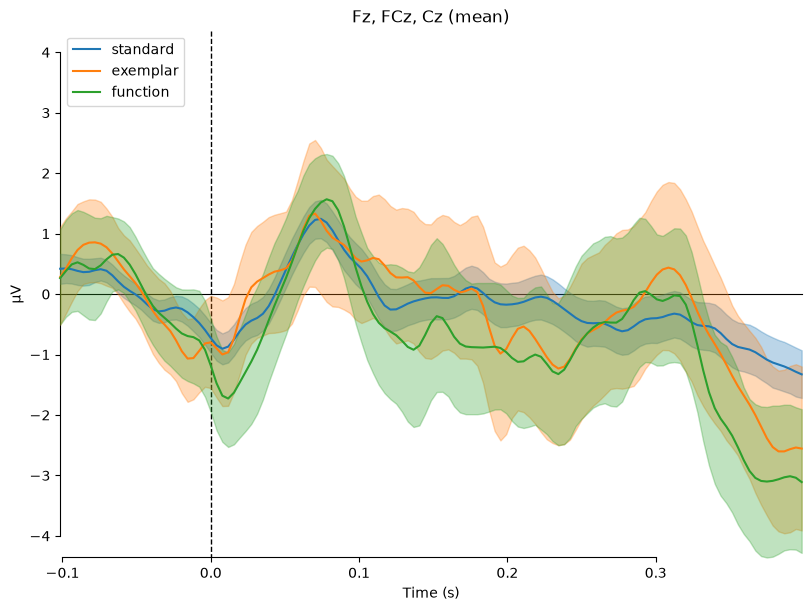

In [37]:
# Each kept trial grouped by condition, so the plot can show confidence bands
by_condition = {condition: list(epochs[condition].iter_evoked()) for condition in codes}

# Average response of each condition, mean of Fz, FCz and Cz, with 95% confidence bands
mne.viz.plot_compare_evokeds(by_condition, picks=["Fz", "FCz", "Cz"], combine="mean");

**Result:** all three conditions show a clear response to the chord, a positive peak about 0.07 s after it, then drift negative towards the third chord. Both deviant types dip below standards at times (around 0.2 s and after 0.33 s), function deviants more so. But the confidence bands overlap throughout, and function deviants also dip just after 0 s, too early to be a response to the chord. With only about 110 trials of each deviant type, one participant can't show whether the difference is real; the average across all 30 participants (after step 11) will.

### Step 11: Clean every participant

Steps 3–9 are combined into one function, `clean_participant`, which is run on each of the 30 participants in turn. Each participant's cleaned trials are saved in the `Cleaned` folder (ignored by git) as an MNE file, e.g. `sub-002-epo.fif`, with each trial's row number in the trial table and the number of blink components ICA removed. If a participant's file already exists, it is loaded instead of cleaned again, so rerunning takes seconds instead of about 7 minutes. **After changing any cleaning setting, delete the `Cleaned` folder** so everyone is cleaned again with the new settings.

The noise rule is applied to every participant here, which completes the `kept` and `drop_reason` columns, and the finished trial table is saved as `Cleaned/trials.csv`. Each participant's average response to each condition is also kept, for the check below.

In [38]:
def clean_participant(participant):
    # Step 3: load, cut at the last recorded sample, fix the channel name and positions, mark stuck channels as bad
    raw = mne.io.read_raw_eeglab(next(root.glob(f"{participant}/eeg/*_eeg.set")))
    raw.crop(tmax=(fdt_report["n_samples"][participant] - 1) / raw.info["sfreq"])
    raw.load_data()
    raw.rename_channels({"Afz": "AFz"})
    raw.set_montage("biosemi64")
    stuck = fdt_report["channels_stuck_at_limit"][participant]
    raw.info["bads"] = [] if stuck == "none" else stuck.split(", ")

    # Step 4: downsample to 256 samples per second
    raw.resample(256, method="polyphase")

    # Step 5: keep 0.5 to 40 Hz, filtering each block separately
    raw.filter(l_freq=0.5, h_freq=40, skip_by_annotation="boundary")

    # Step 6: remove the blink components found by ICA
    ica = mne.preprocessing.ICA(n_components=20, random_state=97, max_iter="auto")
    ica.fit(raw.copy().filter(l_freq=1, h_freq=None, skip_by_annotation="boundary"))
    ica.exclude, _ = ica.find_bads_eog(raw, ch_name="Fp2", measure="correlation", threshold=0.7)
    ica.apply(raw)

    # Step 7: channels over 150 µV in more than 10% of trials are noisy; fill in all bad channels
    recorded_trials = trials[(trials["participant"] == participant) & trials["recorded"]]
    test_epochs = mne.Epochs(raw.copy().set_eeg_reference("average"), trial_events(recorded_trials), codes,
                             tmin=-0.1, tmax=0.4, baseline=(None, 0), preload=True).pick("eeg", exclude="bads")
    pct_over = (np.ptp(test_epochs.get_data(), axis=2) > 150e-6).mean(axis=0) * 100
    raw.info["bads"] += [ch for ch, pct in zip(test_epochs.ch_names, pct_over) if pct > 10]
    # Record the filled-in channels in the saved file
    raw.info["description"] = ", ".join(raw.info["bads"]) or "none"
    if raw.info["bads"]:
        raw.interpolate_bads()

    # Step 8: average reference
    raw.set_eeg_reference("average")

    # Step 9: cut the remaining trials from -0.1 to 0.4 s and drop those over 150 µV,
    # keeping each trial's row number in the trial table and the number of blink components removed
    remaining = trials[(trials["participant"] == participant) & trials["drop_reason"].isna()]
    metadata = pd.DataFrame({"row": remaining.index, "condition": remaining["condition"],
                             "blink_components": len(ica.exclude)})
    return mne.Epochs(raw, trial_events(remaining), codes, tmin=-0.1, tmax=0.4, baseline=(None, 0),
                      reject=dict(eeg=150e-6), metadata=metadata, preload=True)

In [39]:
cleaned_folder = Path("Cleaned")
cleaned_folder.mkdir(exist_ok=True)

# The noise rule is redone for everyone here (step 9 only did sub-002)
trials.loc[trials["drop_reason"] == "too noisy", "drop_reason"] = None

filled_in = {}
blink_components = {}
averages = {condition: [] for condition in codes}
for participant in included.index:
    # Clean the participant, or load their cleaned trials if already saved
    file = cleaned_folder / f"{participant}-epo.fif"
    if file.exists():
        epochs = mne.read_epochs(file)
    else:
        epochs = clean_participant(participant)
        epochs.save(file)

    # Trials that were checked but aren't in the cleaned file were too noisy
    remaining = trials.index[(trials["participant"] == participant) & trials["drop_reason"].isna()]
    trials.loc[remaining.difference(epochs.metadata["row"]), "drop_reason"] = "too noisy"

    # Filled-in channels, blink components removed, and the average response to each condition
    filled_in[participant] = epochs.info["description"]
    blink_components[participant] = epochs.metadata["blink_components"].iloc[0]
    for condition in codes:
        averages[condition].append(epochs[condition].average())

trials["kept"] = trials["drop_reason"].isna()
trials.to_csv(cleaned_folder / "trials.csv", index=False)

The check cell shows:
- each participant's filled-in channels (stuck or noisy), the number of blink components ICA removed, and the number of trials dropped for each reason, and any participant with more than 6 filled-in channels (should be none)
- the percentage of checked trials that were too noisy, by group and condition (the noise rule should not hit one condition or group much harder)
- the number of kept trials in each condition, by group (the class balance)
- the average response to each condition across the 30 participants at Fz, FCz and Cz, with 95% confidence bands from the variation between participants (each participant's average counts once)
- scalp maps of the average difference between each deviant type and standards (blue = more negative for deviants)

drop_reason,filled_in,blink_components,first 8 of block,kept,not recorded,too noisy
participant,,,,,,
sub-001,none,1,64,1251,113,12
sub-002,Fp1,1,64,1360,0,16
sub-006,"Fp1, FC2",1,64,1211,0,165
sub-008,"Fp1, P3",1,64,1354,0,22
sub-009,"Fp1, Fpz",1,64,1319,0,57
sub-011,none,1,64,1307,0,69
sub-012,none,1,64,1346,0,30
sub-014,Fp1,1,64,1318,0,58
sub-015,Fp1,1,64,1298,0,78


More than 6 filled-in channels: none


condition,exemplar,function,standard
group,,,
Cl,3.4,3.2,4.2
Imp,2.8,2.6,2.9


condition,exemplar,function,standard,All
group,,,,
Cl,1254,1283,13197,15734
Imp,1898,1941,20112,23951
All,3152,3224,33309,39685


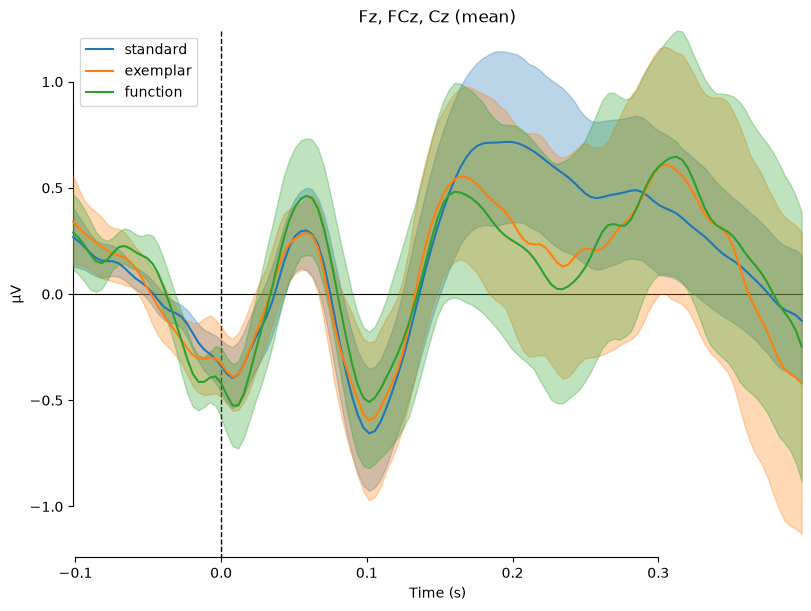

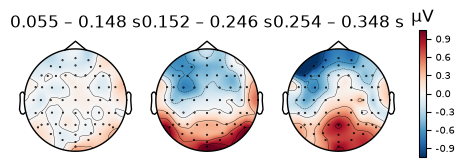

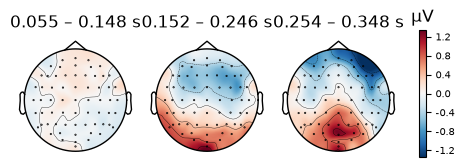

In [40]:
# Each participant's filled-in channels, blink components removed, and trials dropped for each reason
per_participant = pd.crosstab(trials["participant"], trials["drop_reason"].fillna("kept"))
per_participant.insert(0, "filled_in", pd.Series(filled_in))
per_participant.insert(1, "blink_components", pd.Series(blink_components))
display(per_participant)

# Participants with more than 6 filled-in channels (would be excluded)
n_filled = pd.Series({p: 0 if ch == "none" else len(ch.split(", ")) for p, ch in filled_in.items()})
print("More than 6 filled-in channels:", list(n_filled.index[n_filled > 6]) or "none")

# Percentage of checked trials that were too noisy, by group and condition
checked = trials[trials["drop_reason"].isna() | (trials["drop_reason"] == "too noisy")]
display(pd.crosstab(checked["group"], checked["condition"], values=checked["drop_reason"] == "too noisy",
                    aggfunc="mean").mul(100).round(1))

# Number of kept trials in each condition, by group
kept = trials[trials["kept"]]
display(pd.crosstab(kept["group"], kept["condition"], margins=True))

# Average response to each condition across participants, mean of Fz, FCz and Cz
mne.viz.plot_compare_evokeds(averages, picks=["Fz", "FCz", "Cz"], combine="mean");

# Scalp maps of each deviant type minus standards, averaged across participants
standard = mne.grand_average(averages["standard"])
for deviant in ["exemplar", "function"]:
    difference = mne.combine_evoked([mne.grand_average(averages[deviant]), standard], weights=[1, -1])
    difference.plot_topomap(times=[0.1, 0.2, 0.3], average=0.1, ch_type="eeg");

**Result:**
- Steps 6 and 7 recover most of the trials a first version of this cleaning dropped: the noise rule now drops 3.3% of checked trials (1,373 of 41,058) instead of 14%. The most any participant loses is 12% (sub-006 and sub-036), down from 73%.
- ICA removed one blink component for 29 participants; for sub-039 no component matched Fp2 closely enough, and few of its trials are too noisy (1.2%), so nothing large was missed.
- Each participant has at most 3 filled-in channels: the stuck ones, plus FC2 for sub-006, TP8 for sub-030 and C4 for sub-036. Nobody is excluded.
- The noise rule drops slightly more `Cl` trials (3.2–4.2%) than `Imp` trials (2.6–2.9%), and slightly more standards than deviants, but the gaps are now small (in the first version: 15–20% against 8–11%).
- 39,685 trials are kept: 33,309 standard, 3,152 exemplar and 3,224 function (deviants 16%).
- Across participants, all three conditions show the usual response to a chord (peaks at about 0.06, 0.1 and 0.2 s). Both deviant types are more negative than standards from about 0.15 to 0.28 s over the centre of the head, with a positive area at the back: the typical pattern of a brain response to an unexpected sound. It remains after blinks are removed, so it isn't a blink artifact. Function deviants differ slightly more than exemplar deviants. The differences are small (about 0.2–0.4 µV) and within the confidence bands, so telling single trials apart will be hard. The negativity at the front of the head at 0.25–0.35 s may be partly from the eyes.

### Step 12: Extract features

This turns each kept trial's EEG into a few numbers (features) that a model can use, added as columns to the trial table. The result is the table with one row per event, saved as `Cleaned/features.csv`.

#### Drop trials with a button press inside the window

Participants press a button when they hear a deviant. A trial with a press between −0.1 and 0.4 s has hand-movement activity in its EEG, and these trials are about 3 times more common among deviants (2.6%) than standards (0.9%). A model could then learn "movement = deviant" instead of the brain's response to the chord, so these trials are dropped (`button press in window`). Most presses come later, at about 0.7 s, but preparing a movement starts a few hundred milliseconds earlier, so some of it may still fall inside the window for deviants the participant detected. That can't be removed, and is a limitation to keep in mind.

The cell finds every button press (the scored response codes in `events.tsv`) near each trial and drops the kept trials that have one in the window. The check shows the trials dropped for each reason, by condition.

In [41]:
# Button presses are the scored response codes in events.tsv
press_codes = ["Correct - Function!", "Correct - Exemplar!", "Incorrect - Standard!"]

# Whether each trial has a button press between -0.1 and 0.4 s around its middle chord
press_in_window = pd.Series(False, index=trials.index)
for participant in included.index:
    e = events[participant]
    presses = e.loc[e["value"].isin(press_codes), "onset"].to_numpy()
    rows = trials.index[trials["participant"] == participant]
    time_to_press = presses[None, :] - trials.loc[rows, "onset_s"].to_numpy()[:, None]
    press_in_window[rows] = ((time_to_press >= -0.1) & (time_to_press < 0.4)).any(axis=1)

# Drop the kept trials that have one
trials.loc[trials["kept"] & press_in_window, "drop_reason"] = "button press in window"
trials["kept"] = trials["drop_reason"].isna()

# Trials dropped for each reason, by condition
pd.crosstab(trials["drop_reason"].fillna("kept"), trials["condition"], margins=True)

condition,exemplar,function,standard,All
drop_reason,,,,
button press in window,83,84,298,465
first 8 of block,0,0,1920,1920
kept,3069,3140,33011,39220
not recorded,20,12,190,222
too noisy,98,94,1181,1373
All,3270,3330,36600,43200


#### Drop trials near a block edge

The 0.5 Hz filter reaches 3.3 s past each block edge (step 5), so the EEG is slightly distorted that close to the start or end of a block. The first 8 trials of each block already cover block starts, but not block ends. Every participant heard the same trial order, and several blocks happen to end shortly after a function deviant, so these distorted trials are mostly deviants: a model could learn the distortion instead of the brain's response. Trials whose middle chord is closer than 3.3 s to a block edge or the end of the recording are dropped (`near block edge`). Like the other rules, this ignores the condition.

The check shows the trials dropped for each reason, by condition.

In [42]:
# How far the 0.5 Hz filter reaches past a block edge (half its length, as in step 5)
reach = len(mne.filter.create_filter(None, 256, l_freq=0.5, h_freq=None)) / 256 / 2

# Whether each trial's middle chord is closer than that to the start, a join or the end of the recording
near_edge = pd.Series(False, index=trials.index)
for participant in included.index:
    e = events[participant]
    recording_end = fdt_report["n_samples"][participant] / eeg_json_report.loc[participant, "SamplingFrequency"]
    edges = np.r_[0, e.loc[e["value"] == "boundary", "onset"], recording_end]
    rows = trials.index[trials["participant"] == participant]
    distance = np.abs(trials.loc[rows, "onset_s"].to_numpy()[:, None] - edges).min(axis=1)
    near_edge[rows] = distance < reach

# Drop the kept trials that are near an edge
trials.loc[trials["kept"] & near_edge, "drop_reason"] = "near block edge"
trials["kept"] = trials["drop_reason"].isna()

# Trials dropped for each reason, by condition
pd.crosstab(trials["drop_reason"].fillna("kept"), trials["condition"], margins=True)

condition,exemplar,function,standard,All
drop_reason,,,,
button press in window,83,84,298,465
first 8 of block,0,0,1920,1920
kept,3067,3075,32919,39061
near block edge,2,65,92,159
not recorded,20,12,190,222
too noisy,98,94,1181,1373
All,3270,3330,36600,43200


#### Compute the features

The windows and bands come from published research on responses to unexpected sounds and chords, not from our own plots: choosing them by where our deviants differ from standards would use every participant's labels, including those of participants the model is later tested on.

Channels are grouped into 9 scalp regions: front, centre and back, each split into left, middle and right (in channel names, odd numbers are on the left, even numbers on the right, and names ending in "z" are in the middle). For each kept trial and region:
- **amplitude** (`amp_<window>_<region>`, in µV): the average voltage in three windows after the middle chord: `early` (0–0.1 s, the response to the sound itself), `middle` (0.1–0.25 s, where responses to unexpected sounds and chords are usually found) and `late` (0.25–0.4 s, a later response to surprises)
- **power** (`pow_<band>_<region>`, log10 of µV²/Hz): how strong each rhythm is from 0 to 0.4 s, for `theta` (4–8 Hz), `alpha` (8–13 Hz), `beta` (13–30 Hz) and `gamma` (30–40 Hz). It is estimated with MNE's multitaper method, smoothing over 5 Hz so the bands stay separate. Power is very skewed, so it is stored on a log scale. With only 0.4 s of data, theta gets less than two full waves, so its estimates are rough. Beta and gamma power in the left and right regions may partly measure muscle tension around the jaw and temples: some participants have channels there with muscle noise too small for the 150 µV rule to catch (e.g. FT7, T7 and FT8 for sub-035). As noted in step 5, muscle tension could differ between trial types if participants tense up before pressing the button after a deviant, so left and right beta and gamma power should be checked by comparing models with and without them.

That gives 27 amplitude and 36 power features. They use only each trial's own EEG, between the middle chord and the third chord. Dropped trials have empty feature columns. The features are not standardized here: that happens when modelling, fitted on the training participants only.

In [43]:
# Scalp region of a channel: front / centre / back, and left / mid / right
def region(channel):
    if channel.startswith(("Fp", "AF")) or (channel.startswith("F") and not channel.startswith(("FC", "FT"))):
        row = "front"
    elif channel.startswith(("FC", "FT", "C", "T")):
        row = "centre"
    else:
        row = "back"
    if channel.endswith("z"):
        side = "mid"
    else:
        side = "left" if int(channel[-1]) % 2 == 1 else "right"
    return f"{row}_{side}"

windows = {"early": (0, 0.1), "middle": (0.1, 0.25), "late": (0.25, 0.4)}
bands = {"theta": (4, 8), "alpha": (8, 13), "beta": (13, 30), "gamma": (30, 40)}

tables = []
for participant in included.index:
    # This participant's cleaned trials, keeping only the trials still kept
    epochs = mne.read_epochs(cleaned_folder / f"{participant}-epo.fif")
    epochs = epochs[epochs.metadata["row"].isin(trials.index[trials["kept"]]).to_numpy()]
    regions = np.array([region(channel) for channel in epochs.ch_names])
    features = pd.DataFrame(index=epochs.metadata["row"].to_numpy())

    # Amplitude: average voltage in each window, averaged over the channels in each region (µV)
    data = epochs.get_data() * 1e6
    for window, (start, end) in windows.items():
        in_window = (epochs.times >= start) & (epochs.times < end)
        channel_means = data[:, :, in_window].mean(axis=2)
        for r in np.unique(regions):
            features[f"amp_{window}_{r}"] = channel_means[:, regions == r].mean(axis=1)

    # Power: strength of each rhythm from 0 to 0.4 s, averaged over the channels in each region (log10 µV²/Hz)
    # (multitaper method, smoothing over 5 Hz; normalization="full" gives power per Hz)
    power, freqs = epochs.compute_psd(method="multitaper", fmin=4, fmax=40, tmin=0, tmax=0.4, bandwidth=5,
                                      normalization="full").get_data(return_freqs=True)
    for band, (low, high) in bands.items():
        band_power = power[:, :, (freqs >= low) & (freqs < high)].mean(axis=2) * 1e12
        for r in np.unique(regions):
            features[f"pow_{band}_{r}"] = np.log10(band_power[:, regions == r].mean(axis=1))
    tables.append(features)

# Add the features to the trial table (empty for dropped trials) and save it
features = pd.concat(tables)
trials = trials.drop(columns=features.columns, errors="ignore").join(features)
trials.to_csv(cleaned_folder / "features.csv", index=False)

The check cell shows:
- the channels in each region
- the number of kept trials, rows with features, and missing feature values in kept rows (should be equal, equal, and 0)
- the number of kept trials in each condition, by group (the class balance)
- the range of each feature (mean, standard deviation, smallest and largest value)
- the number of values more than 5 standard deviations from their feature's mean
- the average `middle`-window amplitude in the front-middle and centre-middle regions for each condition (deviants should be more negative, as in step 11)

In [44]:
# Channels in each region
display(pd.Series(epochs.ch_names).groupby(regions).agg(list).to_frame("channels"))

# Kept trials, rows with features, and missing feature values in kept rows
feature_columns = list(features.columns)
kept = trials[trials["kept"]]
print("Kept trials:", len(kept), "| Rows with features:", trials[feature_columns].notna().all(axis=1).sum(),
      "| Missing values in kept rows:", kept[feature_columns].isna().sum().sum())

# Kept trials in each condition, by group
display(pd.crosstab(kept["group"], kept["condition"], margins=True))

# Range of each feature
display(kept[feature_columns].describe().T[["mean", "std", "min", "max"]].round(2))

# Values more than 5 standard deviations from their feature's mean
z = (kept[feature_columns] - kept[feature_columns].mean()) / kept[feature_columns].std()
print("Values beyond 5 SD:", int((z.abs() > 5).sum().sum()), "of", z.size)

# Average middle-window amplitude in the front-middle and centre-middle regions, by condition (µV)
kept.groupby("condition")[["amp_middle_front_mid", "amp_middle_centre_mid"]].mean().round(2)

,channels
back_left,"[P1, P3, P5, P7, P9, PO7, PO3, O1]"
back_mid,"[Iz, Oz, POz, Pz]"
back_right,"[P2, P4, P6, P8, P10, PO8, PO4, O2]"
centre_left,"[FT7, FC5, FC3, FC1, C1, C3, C5, T7, TP7, CP5,..."
centre_mid,"[CPz, FCz, Cz]"
centre_right,"[FT8, FC6, FC4, FC2, C2, C4, C6, T8, TP8, CP6,..."
front_left,"[Fp1, AF7, AF3, F1, F3, F5, F7]"
front_mid,"[Fpz, AFz, Fz]"
front_right,"[Fp2, AF8, AF4, F2, F4, F6, F8]"


Kept trials: 39061 | Rows with features: 39061 | Missing values in kept rows: 0


condition,exemplar,function,standard,All
group,,,,
Cl,1185,1194,12909,15288
Imp,1882,1881,20010,23773
All,3067,3075,32919,39061


,mean,std,min,max
amp_early_back_left,0.25,3.46,-32.20,20.86
amp_early_back_mid,0.29,3.84,-24.20,30.02
amp_early_back_right,0.20,3.58,-29.39,26.67
amp_early_centre_left,-0.01,2.54,-24.94,22.81
amp_early_centre_mid,0.01,3.04,-27.68,30.39
...,...,...,...,...
pow_gamma_centre_mid,-1.34,0.30,-2.50,1.11
pow_gamma_centre_right,-0.86,0.42,-1.92,0.91
pow_gamma_front_left,-0.80,0.43,-2.10,1.01
pow_gamma_front_mid,-1.05,0.37,-2.29,0.66


Values beyond 5 SD: 2175 of 2460843


,amp_middle_front_mid,amp_middle_centre_mid
condition,,
exemplar,-0.56,0.55
function,-0.54,0.54
standard,-0.34,0.61


**Result:**
- 465 kept trials had a button press in the window and are dropped (83 exemplar, 84 function, 298 standard).
- 159 kept trials are near a block edge and are dropped: 65 function, 2 exemplar and 92 standard. That is 2.1% of function trials against 0.3% of standards, so the distortion was linked to the label.
- 39,061 trials are kept: 32,919 standard, 3,067 exemplar and 3,075 function (deviants 16%).
- Every kept trial has all 63 features, with no missing values; dropped trials have none.
- Amplitude features are in µV: they average near 0, with standard deviations of 2.5–8 µV (largest at the front of the head) and extremes of about ±70 µV. Power features are in log10 µV²/Hz, from about −2.5 to 2.2, with standard deviations of 0.3–0.5. The two kinds are on very different scales, so they need standardizing for models such as logistic regression.
- 0.09% of values are more than 5 standard deviations from their feature's mean, almost all of them amplitudes. Every trial already passed the 150 µV rule, so these are kept as real, if unusual, trials.
- As in step 11, deviants are slightly more negative than standards in the `middle` window: −0.56 µV (exemplar) and −0.54 µV (function) against −0.34 µV (standard) over the front-middle region, and 0.55 and 0.54 µV against 0.61 µV over the centre-middle region.

### Log: milestone checks

What each step found and decided, for the report and slides.

| Step | Check | Found | Decision and why |
|---|---|---|---|
| 1 | Missing data | 10 recordings are 1–8% recorded; sub-001 and sub-030 are 92%. | Exclude the 10: 0–15 deviants each is too few to test on, and imputing from other participants would invent data and leak it between training and test participants; keep the 2 partial ones with only their recorded trials, giving 30 participants. |
| 1 | Missing data pattern | All 10 excluded are `Cl` women or `Imp` men. | Note as a limitation: group and gender stay linked. |
| 1 | Unusual values | Only age outlier (42) is an excluded participant. | No action needed. |
| 2 | Class imbalance | Each participant has 1,220 standard (84.7%), 109 exemplar (7.6%) and 111 function (7.7%) trials. | Note now: use balanced accuracy or AUC and compare with an "always standard" baseline; consider class weights. |
| 2 | Missing data | 113 trials of sub-001 and 109 of sub-030 fall after their recording ends. | Keep the rows with `recorded` = false so the table has every event; leave them out of EEG analysis. |
| 2 | Unusual values | Every middle chord is exactly 0.4 s after the first chord; trials within a block are 1.57–1.78 s apart. No timing errors. | No action needed. |
| 2 | Information leakage | `correct` is scored from a button press after the chord. `block`, `trial` and `onset_s` reveal the condition, because every participant heard the same trial order. | Kept for checking and grouping only, never as model features. |
| 3 | Unusual values | Channels stuck at the recording limit hold no EEG (Fp1 for sub-002); channel `Afz` is misspelled. | Mark stuck channels as bad so later steps leave them out; rename `Afz` to `AFz`. |
| 3 | Missing data | MNE can't load sub-001 and sub-030 as they are, because their files stop early. | Cut each recording at its last recorded sample before loading. |
| 5 | Unusual values | Raw channels drift slowly and carry 60 Hz mains hum (a peak 24 dB above nearby frequencies). Both are real signals, but not brain responses. | Filter 0.5–40 Hz, one block at a time. 0.5 Hz rather than 0.1 Hz: it affects 2 trials near block edges instead of 104 (sub-002), with the same average response. Trials that close to a block edge are dropped in step 12. |
| 5 | Information leakage | Activity above 40 Hz is mostly muscle, which could differ between trial types because of preparing the button press. | Remove everything above 40 Hz, so frequency features stop at low gamma. |
| 6 | Unusual values | Blinks: large swings on the front channels, the main reason trials were dropped in a first version of the cleaning (14% overall, up to 41% per participant). | Remove the blink component found by ICA (matched to Fp2): one per participant, none for sub-039. ICA is fitted per participant without the trial labels. |
| 7 | Unusual values | A few channels are noisy for much of the recording (in a first version, C4 dropped 69% of sub-036's trials and TP8 67% of sub-030's). | Channels over 150 µV in more than 10% of trials count as noisy. A participant with more than 6 bad channels would be excluded (none is). |
| 7 | Missing data | Stuck and noisy channels hold no usable EEG. | Fill them in from neighbouring channels: the rest of the head was recorded at the same moments. |
| 8 | Scale of features | Raw channels vary by 22–2,874 µV (median standard deviation per participant), mostly offsets and drift. After cleaning, sub-002's channels vary by about 4–17 µV. | Average reference, so channels are on the same footing. Features computed later will still be on different scales (µV vs µV²), so they will be standardized when modelling, using training participants only. |
| 9 | Missing data | 64 standards per participant are the first 8 of their block. sub-002 loses 16 trials as too noisy, about equally across conditions (1.2% of standards, 0.9% of deviants). | Keep every row; `kept` and `drop_reason` record which trials are used and why. |
| 9 | Unusual values | Trials where a channel still swings by more than 150 µV after blinks and noisy channels are dealt with (for sub-002, mostly CP3). | Dropped as too noisy. |
| 9 | Class imbalance | After dropping, sub-002 keeps 1,142 standard, 108 exemplar and 110 function trials (deviants 16%). | Imbalance about the same as before; same plan as step 2. |
| 9 | Information leakage | The first 8 trials of every block are always standards. | Dropped. `kept` and `drop_reason` are never features, and the drop rules ignore the condition. |
| 11 | Missing data | A first version without steps 6–7 dropped 14% of checked trials as too noisy (0.3–73% per participant; five participants over 35%), from blinks or a single noisy channel. With steps 6–7: 3.3% (1,373 trials), at most 12% for any participant. | Keep all 30 participants; every trial stays in the table with `kept` and `drop_reason`. |
| 11 | Missing data pattern | Slightly more `Cl` trials are dropped (3.2–4.2%) than `Imp` (2.6–2.9%), and slightly more standards than deviants (first version: 15–20% against 8–11%). | Small enough to accept; note as a limitation. |
| 11 | Class imbalance | 39,685 trials kept: 33,309 standard, 3,152 exemplar, 3,224 function (deviants 16%). | Same plan as step 2: balanced accuracy or AUC, "always standard" baseline, class weights. |
| 12 | Information leakage | Button presses within −0.1 to 0.4 s are about 3 times more common for deviants (2.6%) than standards (0.9%). | Drop those 465 trials. Preparing a later press may still begin inside the window for detected deviants: a limitation for the report. |
| 12 | Information leakage | Choosing feature windows from our own deviant–standard plots would use the labels of participants the model is tested on. | Windows and bands taken from published research. Features use only each trial's own EEG between the middle and third chords. |
| 12 | Information leakage | The filter distorts the EEG within 3.3 s of a block edge. Block starts are already dropped (first 8 trials), but several blocks end shortly after a function deviant, so 2.1% of function trials are near an edge against 0.3% of standards. | Drop those 159 trials (`near block edge`). The rule ignores the condition. |
| 12 | Missing data | Features exist for the 39,061 kept trials, with no missing values. | Model on kept trials only; dropped trials have empty feature columns. |
| 12 | Scale of features | Amplitudes in µV (standard deviation 2.5–8, extremes about ±70); power in log10 µV²/Hz (−2.5 to 2.2, standard deviation 0.3–0.5). | Standardize when modelling, fitted on training participants only (not needed for decision trees). |
| 12 | Unusual values | 0.09% of feature values are more than 5 standard deviations from their mean, almost all amplitudes. | Kept: every trial passed the 150 µV rule, so these are real trials. Power is on a log scale to reduce skew. |
| 12 | Class imbalance | 39,061 kept trials: 32,919 standard, 3,067 exemplar, 3,075 function (deviants 16%). | Same plan as step 2. |
| 12 | Unusual values | Some channels on the sides of the head carry muscle noise (jaw and temples) too small for the 150 µV rule, e.g. FT7, T7 and FT8 for sub-035. | Kept, as a limitation: muscle tension could differ between trial types (step 5), so left and right beta and gamma power may partly reflect it. Compare models with and without them. |

### Project question and plan

#### 1. Project question

We keep the original question, made more precise:

> Can EEG activity in the 0.4 s after a chord tell an expected (standard) chord from an unexpected (deviant) one, in participants the model has never seen? Which EEG features are most informative, and do the two kinds of deviant (exemplar and function) produce different responses?

What changed and why:
- **The unit of prediction is precise:** one middle chord heard by one participant, labelled standard or deviant.
- **The main task is two classes (standard vs deviant).** Comparing exemplar and function deviants becomes the second question, because each has only about 3,000 trials.
- **Generalizing to new people is the test:** the model is always tested on participants it wasn't trained on (a staff condition).

Why it can be answered: there are 39,061 labelled trials, with about 3,000 of each deviant type, and averaged across participants deviants are more negative than standards from about 0.15 to 0.28 s over the centre of the head, the typical brain response to an unexpected sound (step 11). But the difference is small (about 0.2–0.4 µV, while single trials vary by 2.5–8 µV), so classifying single trials will be hard, and a modest result above baseline would still be meaningful.

#### 2. The data

- **Source:** "EEG: Improvisation and Musical Structures" (Goldman et al., 2020), on NEMAR at [doi.org/10.82901/nemar.on003570](https://doi.org/10.82901/nemar.on003570), a copy of OpenNeuro `ds003570` (CC0 license).
- **Raw data:** 40 musicians (16 classical, `Cl`; 24 jazz improvisers, `Imp`; aged 18–42), 64-channel EEG at 2,048 samples per second, about 39 GB.
- **Task:** participants heard 1,440 three-chord progressions. The middle chord was usually the expected one (85%), and sometimes an unexpected chord (exemplar deviant, 7.6%) or a chord with a different harmonic function (function deviant, 7.7%). They pressed a button when they heard a deviant.
- **Table after cleaning:** `Cleaned/features.csv`, **43,200 rows × 75 columns**. One row is one middle chord heard by one participant (30 participants × 1,440). **39,061 rows are kept for modelling**; the others stay in the table with `kept` = False and a `drop_reason`.
  - 12 bookkeeping columns: `participant`, `group`, `block`, `trial`, `onset_s`, `code`, `chord`, `condition` (the label), `correct`, `recorded`, `drop_reason`, `kept`
  - 63 EEG features: 27 amplitude features (average voltage in 3 time windows × 9 scalp regions) and 36 power features (4 frequency bands × 9 regions)

#### 3. What we learned that changes the plan

- **Missing data:** 10 of 40 recordings were published cut off (1–8% present), so they are excluded; too little of each exists to impute. sub-001 and sub-030 (92% present) keep only their recorded trials. That leaves 30 participants: 12 `Cl` and 18 `Imp`.
- **Group and gender are linked:** women are 8 of 12 `Cl` but 4 of 18 `Imp`, so any group comparison is also a gender comparison and can only be exploratory.
- **Class imbalance:** 84% standard, 8% exemplar, 8% function. "Always standard" already scores 84% accuracy, so we use balanced accuracy or ROC AUC and consider class weights.
- **Columns that leak the label, never used as features:** `code` contains the label; `correct` comes from a button press after the chord; `block`, `trial` and `onset_s` reveal the condition, because every participant heard exactly the same sequence (the README wrongly says it was shuffled); `kept` and `drop_reason` are bookkeeping.
- **Leaks in the EEG itself, fixed by dropping trials:** the first 8 trials of every block are always standards (1,920 dropped); button presses inside the window are 3 times more common for deviants (465 dropped); the filter distorts trials near block edges, which were mostly function deviants (159 dropped). Feature windows and bands come from published research, not our own plots.
- **Unusual values:** many recordings have a channel stuck at the recording limit (Fp1 in 26 of 40), filled in from neighbouring channels; blinks are removed with ICA; 1,373 trials over 150 µV are dropped as too noisy. Some muscle noise remains on side channels, a limitation for interpreting beta and gamma features.
- **Scale:** amplitudes in µV (standard deviation 2.5–8) and power in log units (0.3–0.5) need standardizing, fitted on training participants only.
- **Behaviour (context):** among kept trials, participants detected 77% of function deviants but only 65% of exemplar deviants, and pressed after 6% of standards.

#### 4. Plan for the rest of the project

- **Features:** the 63 above; compare amplitude only, power only and both, to answer which features are most informative.
- **Models:** an always-standard baseline, regularized logistic regression (standardized inside each training fold), a random forest, and shrinkage LDA (a method from outside the course, for AC209A).
- **Evaluation:** cross-validation grouped by participant (e.g. 5 folds of 6 participants, or leaving one participant out at a time); balanced accuracy and ROC AUC, compared with an "always standard" baseline and chance; class weights for the imbalance.
- **Which features matter:** logistic regression coefficients, tree importances, and permutation importance on held-out participants.
- **Second questions:** exemplar vs function deviants; an exploratory look at `Cl` vs `Imp`, with the gender caveat.

#### 5. Staff conditions

| Condition | How we meet it |
|---|---|
| The data are raw EEG, not a table: clean the signals and extract features, such as frequency-band activity, for each event | Done in 12 cleaning steps; every kept event has 63 features, including frequency-band power |
| Signal processing isn't taught and staff can't support it | Standard, widely used MNE-Python functions; each choice was tested on our data and explained in this notebook (e.g. comparing filter settings) |
| A table with one row per event within about two weeks | Ready: `features.csv`, 43,200 rows (one per event) × 75 columns |
| Validation keeps each participant's events in the same training or test group | Cross-validation grouped by participant; standardization and any feature selection fitted on training participants only; feature windows from published research, not our data |